In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent)
            if (p / 'submission/report_cells.py').is_file())
sys.path.insert(0, str(ROOT / 'submission'))
from report_cells import verify, render, figure
verify()
from result_explorer import show_explorer, show_candidates

# PerfPDN
### Circuit-Aware Power Distribution Analysis and Interconnect Reinforcement

**IEEE SSCS Code-a-Chip · ISSCC 2027**

In [2]:
render("authors")

## Abstract

Interconnect resistance changes device-terminal voltages and the circuit performance that depends on them. We present PerfPDN, an open-source workflow for predicting the benefit of conductor widening under metric limits and an area budget. A layout-derived resistance network is solved together with PDK device models in ngspice, establishing the operating point about which adjoint sensitivities relate resistance changes to circuit performance. Two SKY130 amplifier studies compare automatically generated widenings through voltage gain and unity-gain frequency. Adding 9.52 µm² to the common-source ground return improves linear gain by 14.91% and unity frequency by 25.23%. For the inverter amplifier, a 3.68 µm² ground-access widening improves unity frequency by 15.56%, compared with 12.19% for an equal-area supply widening. Both selected changes increase supply current. First-order estimates and shared finite-change predictions are compared with complete ngspice measurements; earlier fixed-span experiments provide the worked methods figures and selected finer-mesh checks.

**Contents:** [Introduction](#introduction) · [Circuits and workflow](#problem) · [Method](#method) · [Implementation](#implementation) · [Experimental setup and validation](#setup) · [Run a study](#native-study) · [Conclusion](#conclusion) · [References](#references)

<a id="introduction"></a>
## 1 Introduction and motivation

A circuit schematic usually represents a supply or ground net as one node, even though its physical implementation contains conductors, contacts and vias with finite resistance. Current flowing through these connections creates spatial voltage differences, which change the voltages actually applied to the devices. In an analog circuit, the resulting bias shift can affect current transfer, transconductance, output resistance and frequency response; its significance depends on the role of the affected connection within the circuit.

The route with the largest supply drop need not cause the largest performance loss. A small voltage change at a sensitive reference device can propagate through a shared bias connection and affect several branches. When routing area is constrained, the benefit of reinforcing that connection must therefore be judged against the circuit requirement and the alternatives available within the same budget.

Sensitivity-based reinforcement and performance-directed power-grid optimization have established foundations. Gala, Su and Sapatnekar studied power/ground optimization using wire widening, decoupling capacitors and adjoint sensitivities <a href="#ref-gala2003">[1]</a>. Kawakami et al. subsequently used timing-error risk caused by IR drop as a direct optimization objective, connecting the power network to its effect on circuit operation <a href="#ref-kawakami2008">[2]</a>. These studies provide the context for the present workflow, whose contribution is an accessible implementation that connects physical geometry, circuit measurements and automatically generated, area-constrained modification proposals using open-source tools.

Once the layout and devices have been solved as a connected circuit, adjoint sensitivities allow physical widenings to be compared before full candidate simulation. Section 2 introduces the circuits and workflow, followed by the electrical model, sensitivity calculation and candidate evaluation in Section 3 and their implementation in Section 4.

<a id="problem"></a>
## 2 Circuits and workflow

The analysis requires a schematic and its layout, together with PDK device models and specified source, input-bias, load, process-corner and temperature conditions. Only the declared nets, layers and width increments are considered for modification, subject to any protected regions. Within this search space, performance targets and acceptance limits establish the circuit requirements against which alternatives can be compared under the area budget.

### 2.1 Circuits used in the report

Two SKY130-based topologies are evaluated in this project (Figure 1). The first is a common-source amplifier with an NMOS transistor, a polysilicon load resistor $R_L$ and an external output capacitance $C_L$. We chose a long supply feeder and a narrow ground-return trace to make the interconnect effects observable in the demonstration layout. Current through the return raises the local source voltage above external ground, changing the DC bias and introducing small-signal feedback through the return resistance. Following this connection from geometry to bias, sensitivity and widening provides a worked example of the method.

In the second circuit, a CMOS inverter is biased for small-signal voltage amplification, with separate resistive LI access routes on VDD and ground. Current through these routes changes both devices' terminal voltages, so widening either route can alter the bias and frequency response of the connected pair. The two alternatives can therefore be compared at equal added area. Both amplifier studies measure low-frequency voltage gain and unity-gain frequency, where the magnitude of the small-signal voltage gain falls to one.

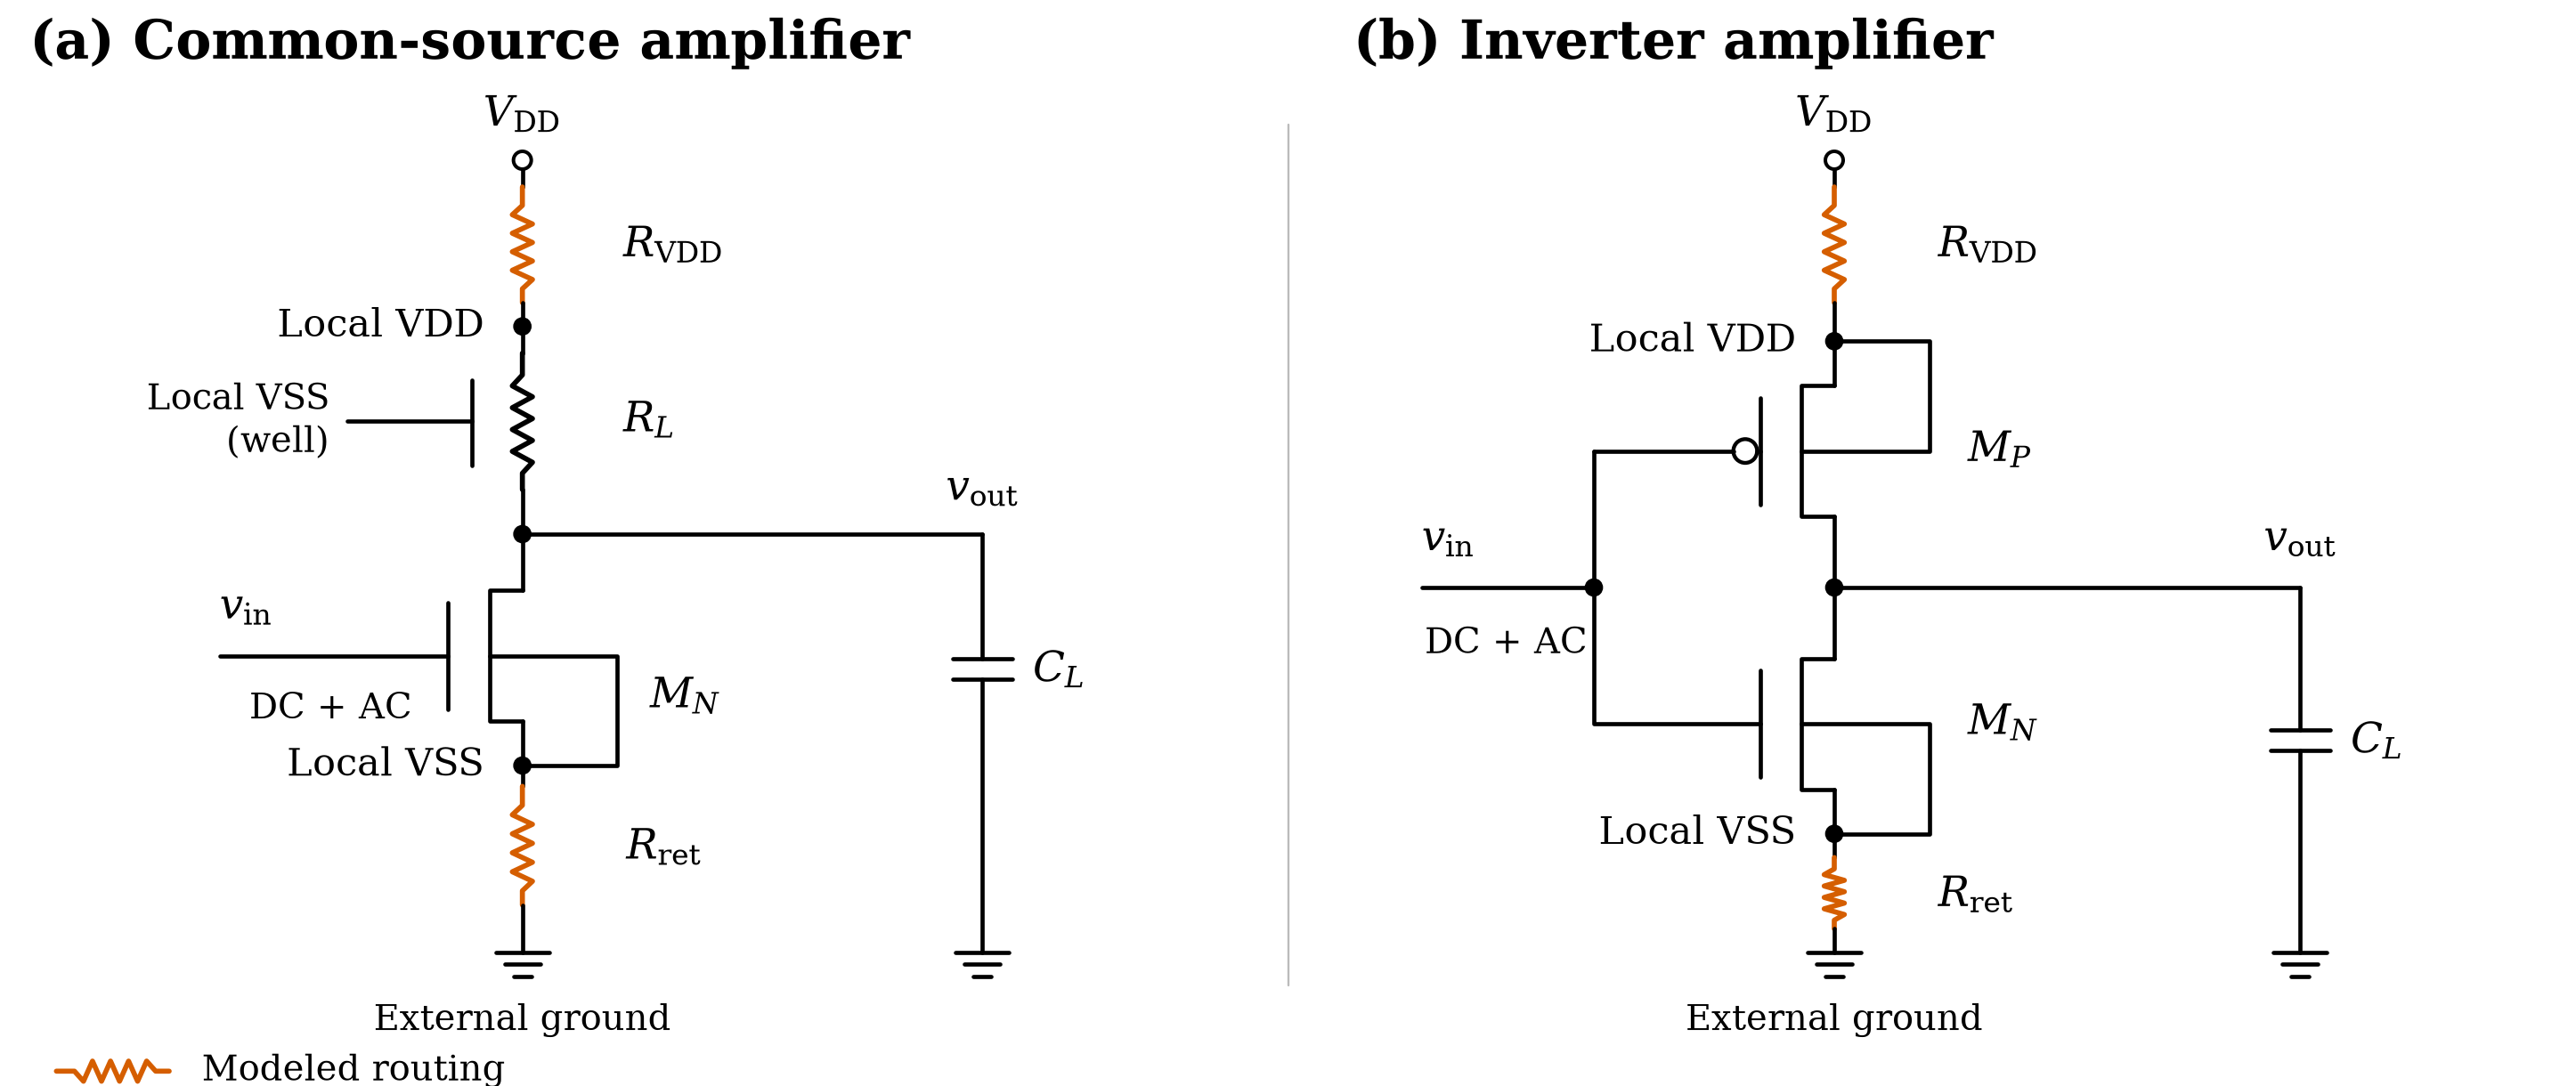

In [3]:
figure("circuits")

*Figure 1. Circuits evaluated for the project. Orange resistors represent distributed VDD and ground connections; source and body ties use the local rails.*

### 2.2 From the connected circuit to a verified widening

Figure 2 follows the common-source return from its layout representation to a verified widening, with an illustrative branched route showing how the search extends across multiple segments.

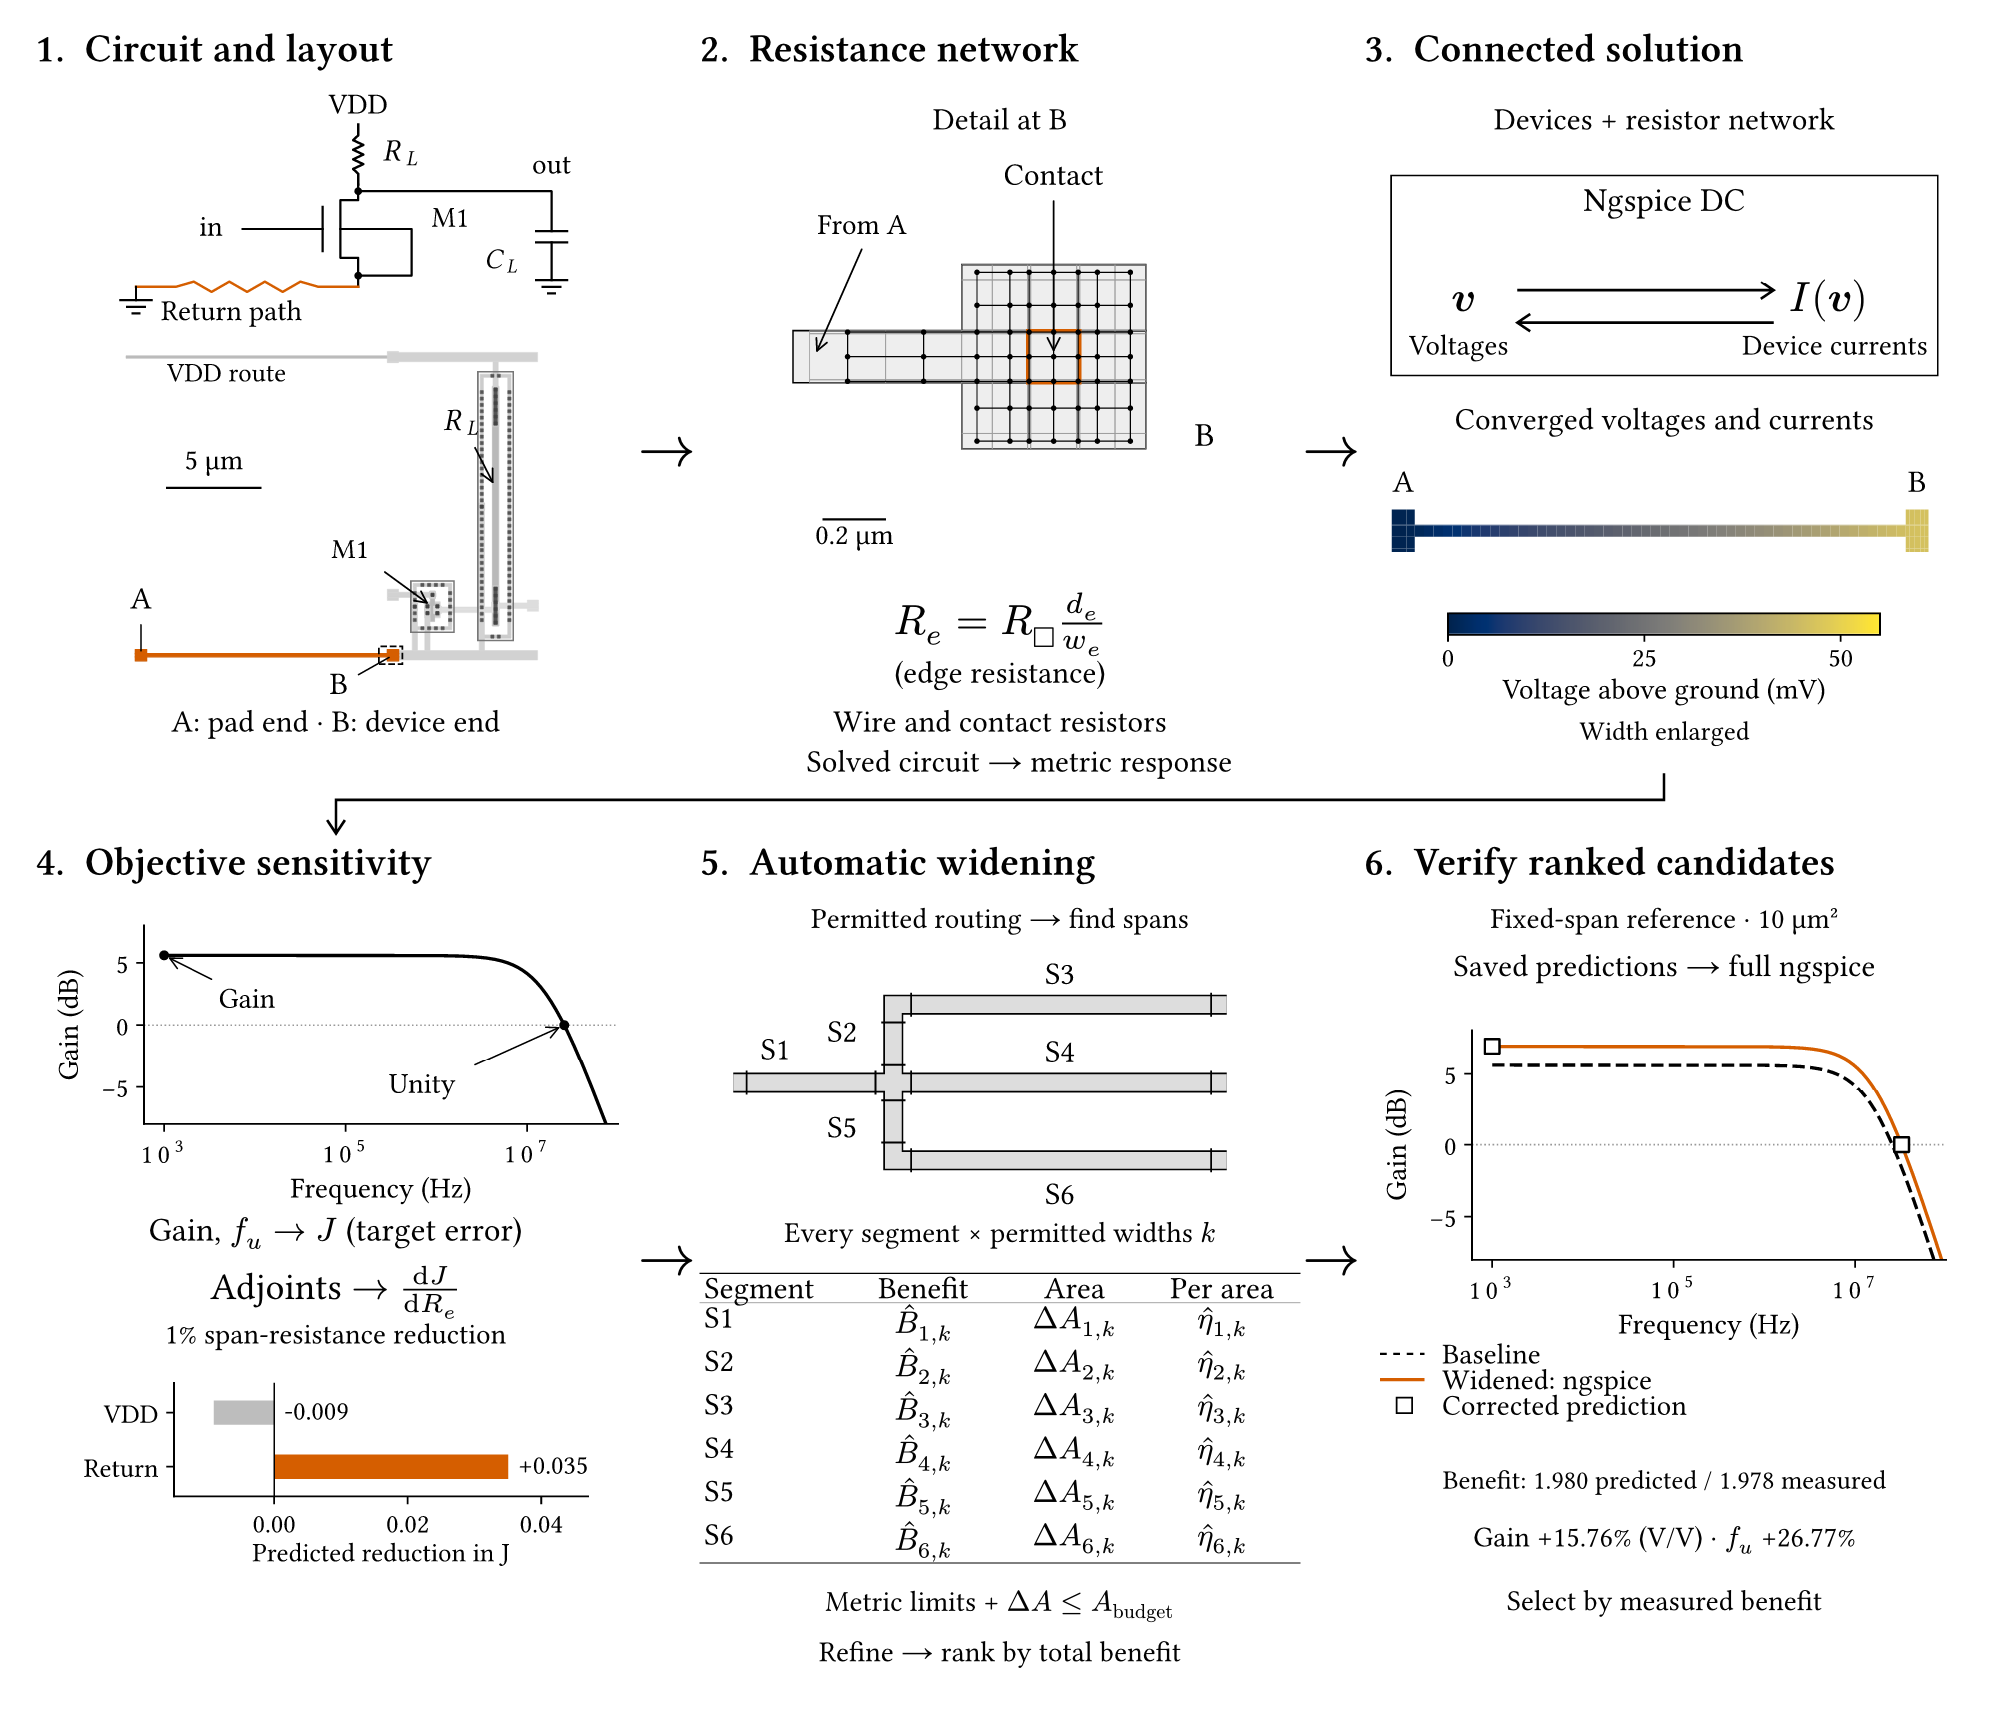

In [4]:
figure("workflow")

*Figure 2. PerfPDN workflow. A and B mark the pad-side and device-side return landings, with a mesh detail at B. The voltage map is referenced to external ground; the sensitivity bars show predicted objective reductions for a 1% decrease in span resistance. Stage 5 illustrates automatic discovery of S1–S6, with each span and width option $k$ assigned a benefit $\widehat B_{i,k}$, area $\Delta A_{i,k}$ and efficiency $\widehat\eta_{i,k}$. Stage 6 shows the saved 10 µm² common-source reference. The experimental setup identifies the numerical cases used in the figures.*

The physical connections must first be included in the circuit so that device loading and interconnect drops can be solved together. Conductor polygons and contact cuts are converted into a resistance network and joined to the devices through their mapped terminals. With geometry and resistance values fixed, ngspice iterates the node voltages and nonlinear device currents until the circuit equations are satisfied. The resulting bias conditions also allow voltage and current to be mapped back onto the layout.

At this converged bias, the chosen performance measurements can be compared with their targets through an objective combining scaled target errors. Their sensitivity to resistance changes provides the basis for evaluating physical modifications: an adjoint calculation gives an initial performance estimate for every permitted width option on every automatically discovered span.

Candidates selected for refinement proceed through geometry modification, design-rule checking (DRC), layout-versus-schematic (LVS) verification and remeshing before their predicted response is updated. Among feasible alternatives within the area budget, the highest total predicted objective benefits receive priority for full ngspice verification. The largest positive measured benefit among feasible verified candidates determines the final choice relative to the unchanged, zero-cost design; benefit per area is reported as an additional efficiency measure.

<a id="method"></a>
## 3 Method

Small circuits with explicit loads and metrics make the operating-point and adjoint calculations easier to follow before their application to the amplifier. For the physical construction, the common-source return appears throughout the mesh, contact and widening figures.

### 3.1 Representing the layout as a resistance network

A drawn conductor occupies an area through which current can take several paths, particularly near bends, branches and connections between layers. We therefore divide the conductor area into smaller regions and connect their electrical representations through finite resistances, allowing the circuit simulation to determine how voltage varies across the layout.

Overlapping shapes on a layer must be merged into their geometric union before meshing, otherwise shared conductor area could be counted more than once. The physical device connections are also mapped to their compact-model terminals at this stage, establishing where the interconnect will join the circuit.

With horizontal and vertical polygon boundaries and right-angle corners, the supported layouts have what is commonly called *Manhattan geometry*. Grid lines can therefore follow every conductor boundary, hole, contact boundary and terminal region by collecting their coordinates and subdividing the intervening distances according to the mesh-spacing settings. Each resulting rectangle lies either within a conductor or outside it, so only occupied rectangles need an electrical representation.

Within each occupied rectangle, or *mesh cell*, the local potential is represented by a node at its center. Resistors between cells sharing a conducting face allow current to follow the occupied area through straight routes, corners and branches; exposed edges have no connection into empty space.

Figure 3 shows this construction and the dimensions used for one cell-to-cell resistance.

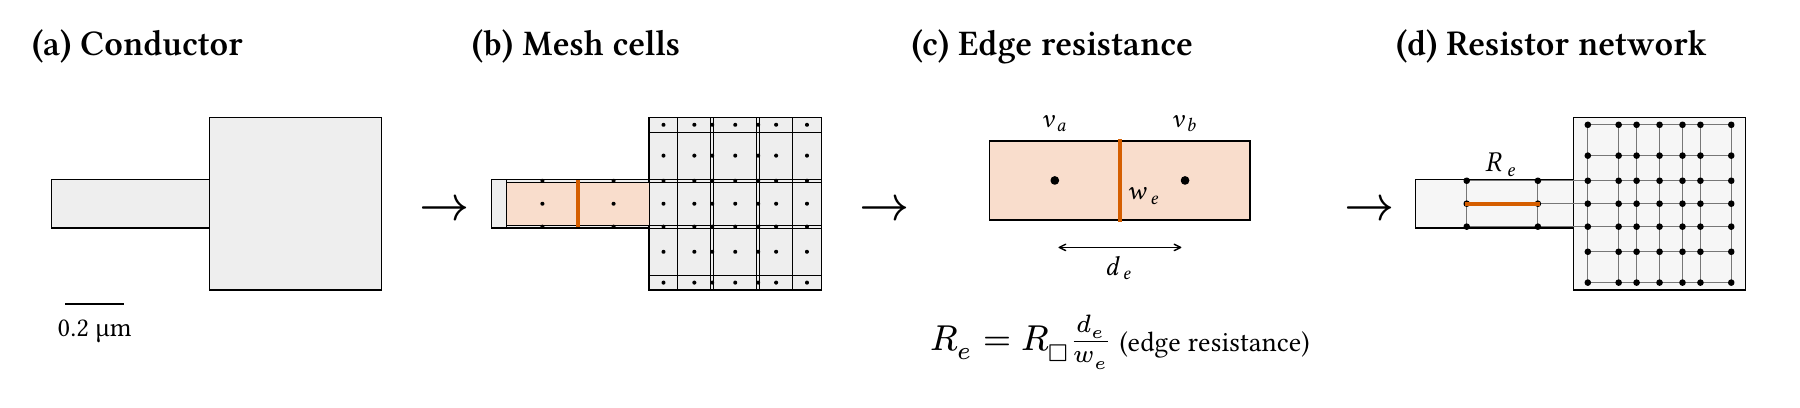

In [5]:
figure("method_mesh")

*Figure 3. From conductor geometry to a resistance network. Panels (a), (b) and (d) show the same layout region at a common scale; (c) enlarges the highlighted cell pair. The center spacing is $d_e$, the shared-face width is $w_e$, and $R_\square$ is the layer sheet resistance.*

For two neighboring cells, the connecting resistor represents current flow from one center to the other through their shared face. Its value is

$$
R_e=R_{\square,\ell}\frac{d_e}{w_e},
$$

where $R_e$ is the resistance of connection $e$, $R_{\square,\ell}$ is the sheet resistance of conductor layer $\ell$, $d_e$ is the distance between the cell centers normal to their shared face, and $w_e$ is the length of that face. In a uniform rectangular strip, this expression reduces to the familiar sheet-resistance relation based on length divided by width.

The shared-face width $w_e$ can be smaller than the trace width when several cells lie across the conductor. Current balance at each free node gives a finite-volume interpretation: currents crossing the cell faces balance those entering or leaving through devices and sources <a href="#ref-eymard2000">[3]</a>.

Short cells near contacts, corners and width transitions resolve variations that a long cell would average over. The interior of a uniform route can be coarser, so additional subdivisions concentrate resolution near the ends of large coordinate intervals.

#### Connecting layers and device terminals

A contact or via between conductor sheets can overlap several mesh cells, although its specified conductance belongs to the physical cut as a whole. Subdivision must therefore distribute that conductance by overlap area to avoid multiplying it with mesh refinement. For a contact with resistance $R_c$ and footprint area $A_c$, overlap $j$ receives

$$
\alpha_j=\frac{A_j}{A_c},
\qquad
g_{c,j}=\frac{\alpha_j}{R_c},
\qquad
\sum_j\alpha_j=1.
$$

Here $A_j$ is the overlap area associated with a connected cell pair, $\alpha_j$ is its dimensionless fraction, and $g_{c,j}$ is its conductance in siemens. When the cells on each side are equipotential, the parallel branches sum to $1/R_c$, matching the specified contact resistance.

The current in each branch follows from its conductance and solved endpoint voltages. The fractions therefore distribute conductance rather than impose current shares, and the physical footprint stays fixed when the surrounding mesh is refined.

A transistor source or another compact-model terminal occupies a physical area called its *terminal footprint*. Cells within this area connect to the terminal node through the modeled contacts. External pin patches are treated as equipotential regions: driven patches have prescribed voltages, and free output-patch voltages follow from the circuit solution. Figure 4 shows how separate local sheet potentials are connected through one contact.

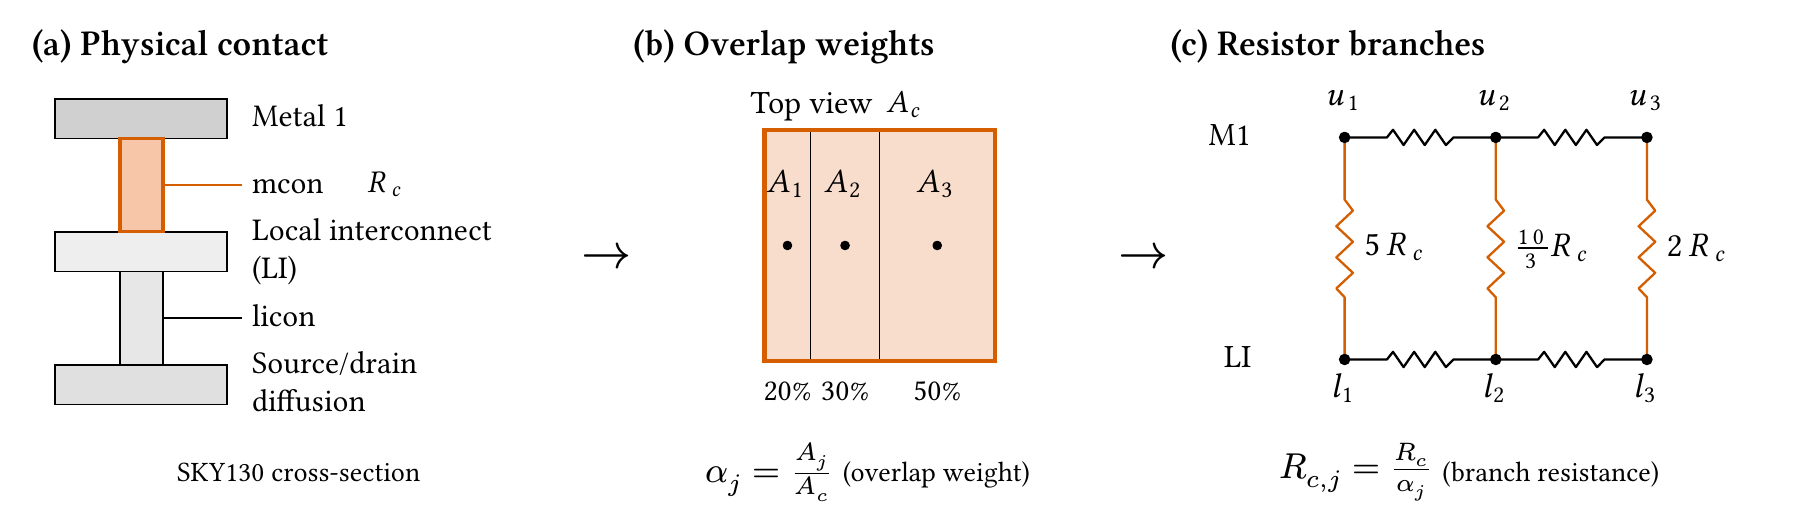

In [6]:
figure("method_contacts")

*Figure 4. A physical contact and its mesh connections. The SKY130 cross-section locates mcon between M1 and LI, above licon and source/drain diffusion. Illustrative overlap fractions of 20%, 30% and 50% give branch resistances $5R_c$, $(10/3)R_c$ and $2R_c$. Each branch joins its own M1 and LI cell potentials, $u_j$ and $l_j$; horizontal resistors represent conduction along the sheets.*

The external mesh begins at the compact-model terminal boundary, accounting for resistance already included in each device model. MOS diffusion-access parameters and the poly resistor's internal and end resistances remain in their PDK models. Table 1 lists the interconnect layers, contact values and model boundaries <a href="#ref-sky130">[4]</a>, <a href="#ref-openpdks">[5]</a>.

In [7]:
render("model_table")

Component,Representation,Parameter or boundary
LI / M1 / M2,Finite-volume sheets,12.8 / 0.125 / 0.125 Ω/□
M3 / M4 / M5,Finite-volume sheets,0.047 / 0.047 / 0.029 Ω/□
MCON / VIA1,Finite cut conductances,9.3 / 4.5 Ω/cut
VIA2 / VIA3 / VIA4,Finite cut conductances,3.41 / 3.41 / 0.38 Ω/cut
N / P diffusion contacts,Explicit cuts at device terminals,185 / 585 Ω/cut
MOS / poly resistor,Pinned compact models,Internal access/end resistance in device models
AC capacitance,Intrinsic device + declared output load,Routing capacitance omitted
External pin patches,Equipotential regions,Driven patches fixed; free output voltages solved


*Table 1. Supported conductor and contact resistances from the pinned technology data, with device, capacitance and source boundaries.*

The resulting graph connects local conductor potentials and device terminals through wire and contact resistances.

### 3.2 Solving for operating point

The device currents and interconnect drops depend on one another. For example, consider a circuit load supplied through resistance $R$ from an external voltage $V_s$. If the voltage at the load is $v$ and its current is $I(v)$, the connection must satisfy

$$
v=V_s-RI(v).
$$

A current obtained at the ideal supply $V_s$ can provide an initial estimate of that loss, but the resulting lower terminal voltage changes the load's operating point and therefore changes the current used in the estimate.

Across multiple transistor terminals and shared bias nodes, these voltage–current dependencies must be satisfied simultaneously. Including the device models, interconnect resistors, external sources and loads in a single SPICE netlist allows ngspice to solve their coupled response.

#### Current balance and its local electrical response

For each free node, Kirchhoff's current law requires the net current leaving the node to equal the externally injected current. A resistor between nodes $i$ and $j$ contributes $g_e(v_i-v_j)$, where $g_e=1/R_e$ is its conductance. A resistor between free node $i$ and a fixed source voltage $V_s$ contributes $g_e(v_i-V_s)$. Device currents add further terms whose values depend on their terminal voltages.

After eliminating the fixed-voltage unknowns from the nodal formulation <a href="#ref-ho1975">[6]</a>, collecting these balances gives the reduced voltage equation

$$
F(\mathbf v,\mathbf g)
=G(\mathbf g)\mathbf v+\mathbf i(\mathbf v)-\mathbf b(\mathbf g)
=\mathbf 0.
$$

For the free node voltages $\mathbf v$ and modeled interconnect conductances $\mathbf g$, the linear network contribution is assembled in $G$. Each resistor between free nodes adds its conductance to their diagonal entries and a negative coupling between them, giving the net resistor current at each node. Currents entering the connected device models are collected in $\mathbf i$, with the same convention of current leaving the network nodes.

Fixed-voltage boundaries also contribute to the balance. In addition to independent current injections in $\mathbf b$, a resistor connected to $V_s$ adds $g_eV_s$ to $\mathbf b$ and $g_e$ to the corresponding diagonal of $G$. Both terms must change if that resistor is modified, and the residual $F$ at a trial voltage vector measures the remaining current imbalance.

The current-balance equation is nonlinear because $\mathbf i(\mathbf v)$ depends on the unknown terminal voltages. A linear approximation around a trial operating point gives a voltage correction, but the corrected voltages generally produce device currents that differ from those predicted by that approximation, leaving a residual in the original balance equation. The simulator must therefore re-evaluate the device response at the new voltages and repeat the correction until the currents and voltages satisfy the nonlinear circuit equations within the specified tolerances.

#### The iteration inside ngspice

Ngspice solves the nonlinear operating point through Newton–Raphson iteration <a href="#ref-ngspice">[7]</a>. At trial voltages $\mathbf v^{(k)}$, it evaluates device currents, the residual $F$, and the current derivatives needed to calculate a voltage correction.

In the reduced notation, these slopes form the current-balance Jacobian

$$
K^{(k)}
=\left.\frac{\partial F}{\partial\mathbf v}\right|_{\mathbf v^{(k)}}
=G+\left.\frac{\partial\mathbf i}{\partial\mathbf v}\right|_{\mathbf v^{(k)}}.
$$

Entry $K_{ij}^{(k)}$ gives the change in current imbalance at node $i$ per volt of change at node $j$, with off-diagonal entries describing coupling between nodes. The wire conductances stay fixed during iteration; the device derivatives are evaluated at each new bias.

Using this local approximation, a voltage correction $\Delta\mathbf v^{(k)}$ is obtained from

$$
K^{(k)}\Delta\mathbf v^{(k)}
=-F(\mathbf v^{(k)},\mathbf g),
\qquad
\mathbf v^{(k+1)}
=\mathbf v^{(k)}+\Delta\mathbf v^{(k)}.
$$

The linear solve gives a correction that cancels the predicted current imbalance. After updating the voltages, ngspice evaluates the nonlinear devices again and repeats the calculation until its voltage and current convergence criteria are satisfied, with device limiting and convergence controls applied as needed.

Figure 5 shows this iteration for a nonlinear load supplied through one resistor. Intersecting the device-current tangent with the wire-current line gives the next voltage estimate; the nonlinear curve then gives the updated current.

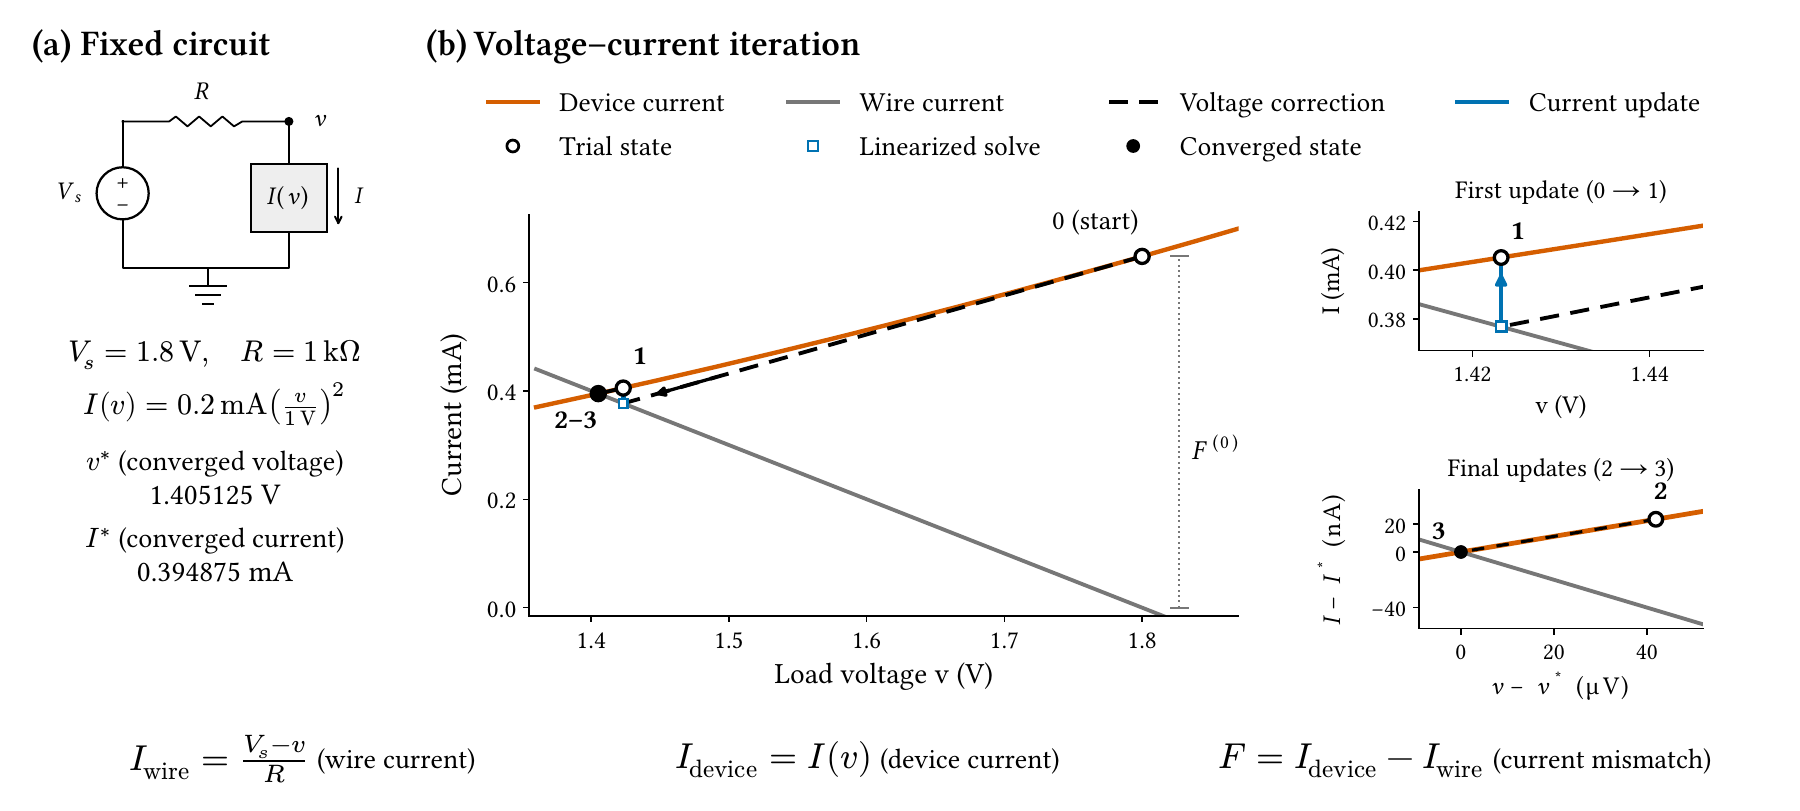

In [8]:
figure("method_operating_point")

*Figure 5. Newton iteration for the circuit in (a), starting at $v^{(0)}=V_s$. Dashed black segments follow device tangents to the wire-current line; blue segments return to the nonlinear curve. Open circles mark trial states, squares mark linearized solutions, and the filled circle marks convergence at $v^*,I^*$. The details resolve the first update and the nearly coincident iterations 2 and 3. The initial current mismatch is $F^{(0)}$.*

#### The solved state

After convergence, Kirchhoff's current law must hold at every free network node, and the net source power must equal the device power plus interconnect losses. PerfPDN checks these conservation relations before evaluating sensitivities, using the tolerances given in Section 4.3. Device-terminal voltages also support inspection of circuit-specific headroom and operating-region requirements.

Branch currents and losses for the spatial maps follow directly from the solved voltages. For an oriented resistor from node $a$ to node $b$,

$$
I_e=\frac{v_a-v_b}{R_e},
\qquad
P_e=I_e^2R_e.
$$

The sign of $I_e$ specifies flow relative to the chosen orientation, and $P_e$ is nonnegative. Dividing current by the shared-face width gives the face-normal sheet current in amperes per meter.

### 3.3 Measuring circuit performance at the solved state

A *performance metric* is a scalar circuit characteristic defined by a measurement procedure, units and reference conditions. DC metrics follow from operating-point voltages and currents. AC metrics require a small-signal simulation using the device conductances and capacitances at that bias.

The current interface measures voltage gain at a specified frequency and the first descending unity-gain crossing within a declared range. A resistance change can affect these measurements through both the AC interconnect and a shift in device bias, whose contributions are derived in Section 3.4. Raw metric values are reported alongside their target errors so each predicted change remains interpretable in physical units.

### 3.4 Calculating how interconnect changes affect performance

Around the converged operating point, a sufficiently small interconnect change can be approximated by the linear response of the connected circuit. External sources and device dimensions remain fixed throughout this calculation, which assumes a nonsingular reduced Jacobian and differentiable device and metric responses.

#### Following one conductance change through the circuit

Let $g_e$ denote the conductance of one resistor and let $\Delta g_e$ be a small change in its value. Holding the node voltages temporarily at their baseline values changes the current carried by that resistor, which creates an imbalance at its connected nodes. The other circuit voltages must then adjust until current balance is restored.

Linearizing the balance around the baseline gives

$$
K\,\Delta\mathbf v
+\frac{\partial F}{\partial g_e}\Delta g_e
\approx\mathbf 0.
$$

Here $K$ is the baseline Jacobian, $\Delta\mathbf v$ is the voltage change, and $\partial F/\partial g_e$ is the current-imbalance change per unit conductance at fixed voltages. This disturbance is local to the resistor endpoints, but the response through $K$ can extend across the circuit.

Moving the local disturbance to the right-hand side expresses it as an equivalent current injection:

$$
\Delta\mathbf b_{\mathrm{eq}}
=-\frac{\partial F}{\partial g_e}\Delta g_e,
\qquad
K\Delta\mathbf v\approx\Delta\mathbf b_{\mathrm{eq}}.
$$

Positive entries of $\Delta\mathbf b_{\mathrm{eq}}$ represent current injected into the corresponding nodes.

Dividing by the conductance perturbation and taking the local limit gives

$$
K\frac{d\mathbf v}{dg_e}
=-\frac{\partial F}{\partial g_e}.
$$

The solution $d\mathbf v/dg_e$ gives the local voltage sensitivity at every free node.

To connect that response to performance, consider first a DC metric $m$ whose dependence on the solved state is known. Its voltage derivative is

$$
\mathbf q_m=\frac{\partial m}{\partial\mathbf v},
\qquad
(\mathbf q_m)_i=\frac{\partial m}{\partial v_i}.
$$

Entry $i$ gives the metric change per volt at $v_i$ with its other arguments fixed. The product $\mathbf q_m^T\Delta\mathbf v$ combines the actual, coupled voltage changes into a first-order metric change.

The chain rule therefore gives

$$
\frac{dm}{dg_e}
=\frac{\partial m}{\partial g_e}
+\mathbf q_m^T\frac{d\mathbf v}{dg_e}.
$$

The first term accounts for explicit conductance dependence in the measurement, such as the current through the altered resistor. The second accounts for the changed node voltages, through which interconnect affects quantities such as the current of an unchanged transistor.

#### The adjoint formulation

The direct approach requires one voltage-response solve for each of $E$ resistors, followed by a scalar product with the metric derivative. For $P$ scalar metrics, an adjoint formulation reduces this to $P$ right-hand-side solutions using the same factorization of $K$. This is useful when the network has many resistors and only a few metrics are needed.

The adjoint changes the order of the calculation by combining the network response with the metric weighting first. The resulting vector can then be paired with the local disturbance from any resistor.

For metric $m$, the required weighting is represented by the adjoint vector $\boldsymbol\lambda_m$, obtained from

$$
K^T\boldsymbol\lambda_m=\mathbf q_m.
$$

At this stage, $K$ is available from the baseline solution and device derivatives, and $\mathbf q_m$ from the metric definition, leaving $\boldsymbol\lambda_m$ as the unknown to solve.

The reason for choosing this equation becomes clear by transposing it to obtain $\boldsymbol\lambda_m^TK=\mathbf q_m^T$. Substituting that identity into the voltage-dependent part of the metric derivative gives

$$
\mathbf q_m^T\frac{d\mathbf v}{dg_e}
=\boldsymbol\lambda_m^T K\frac{d\mathbf v}{dg_e}
=-\boldsymbol\lambda_m^T\frac{\partial F}{\partial g_e}.
$$

The complete voltage-response vector has disappeared from the final expression, leaving

$$
\frac{dm}{dg_e}
=\frac{\partial m}{\partial g_e}
-\boldsymbol\lambda_m^T\frac{\partial F}{\partial g_e}.
$$

Once the adjoint has been solved, evaluating the derivative for another resistor requires its local current-balance contribution and the corresponding adjoint entries. This circuit-sensitivity formulation follows the generalized adjoint-network approach of Director and Rohrer <a href="#ref-director1969">[8]</a>.

Figure 6 applies both calculation paths to a six-node network with internal conductances of $10\,\mathrm{mS}$ and a $20\,\mathrm{mS}$ connection from node 1 to the $1.8\,\mathrm V$ source. Loads $I_3=1\,\mathrm{mS}(v_3-1.2\,\mathrm V)$ and $I_6=2\,\mathrm{mS}(v_6-1.1\,\mathrm V)$ give $K=G+\operatorname{diag}(0,0,1,0,0,2)\,\mathrm{mS}$.

For $m=(0.2v_3+0.8v_6)/(1\,\mathrm V)$, the nonzero weights are $q_3=0.2\,\mathrm V^{-1}$ and $q_6=0.8\,\mathrm V^{-1}$. A 1% increase in $g_{56}$ transfers an additional $6.877\,\mu\mathrm A$ from node 5 to node 6 at the baseline voltages. The direct solve gives $\Delta m\approx2.529\times10^{-4}$; the adjoint values $\lambda_5=84.047\,\mathrm A^{-1}$ and $\lambda_6=120.823\,\mathrm A^{-1}$ give the same change from $(\lambda_6-\lambda_5)\Delta I$.

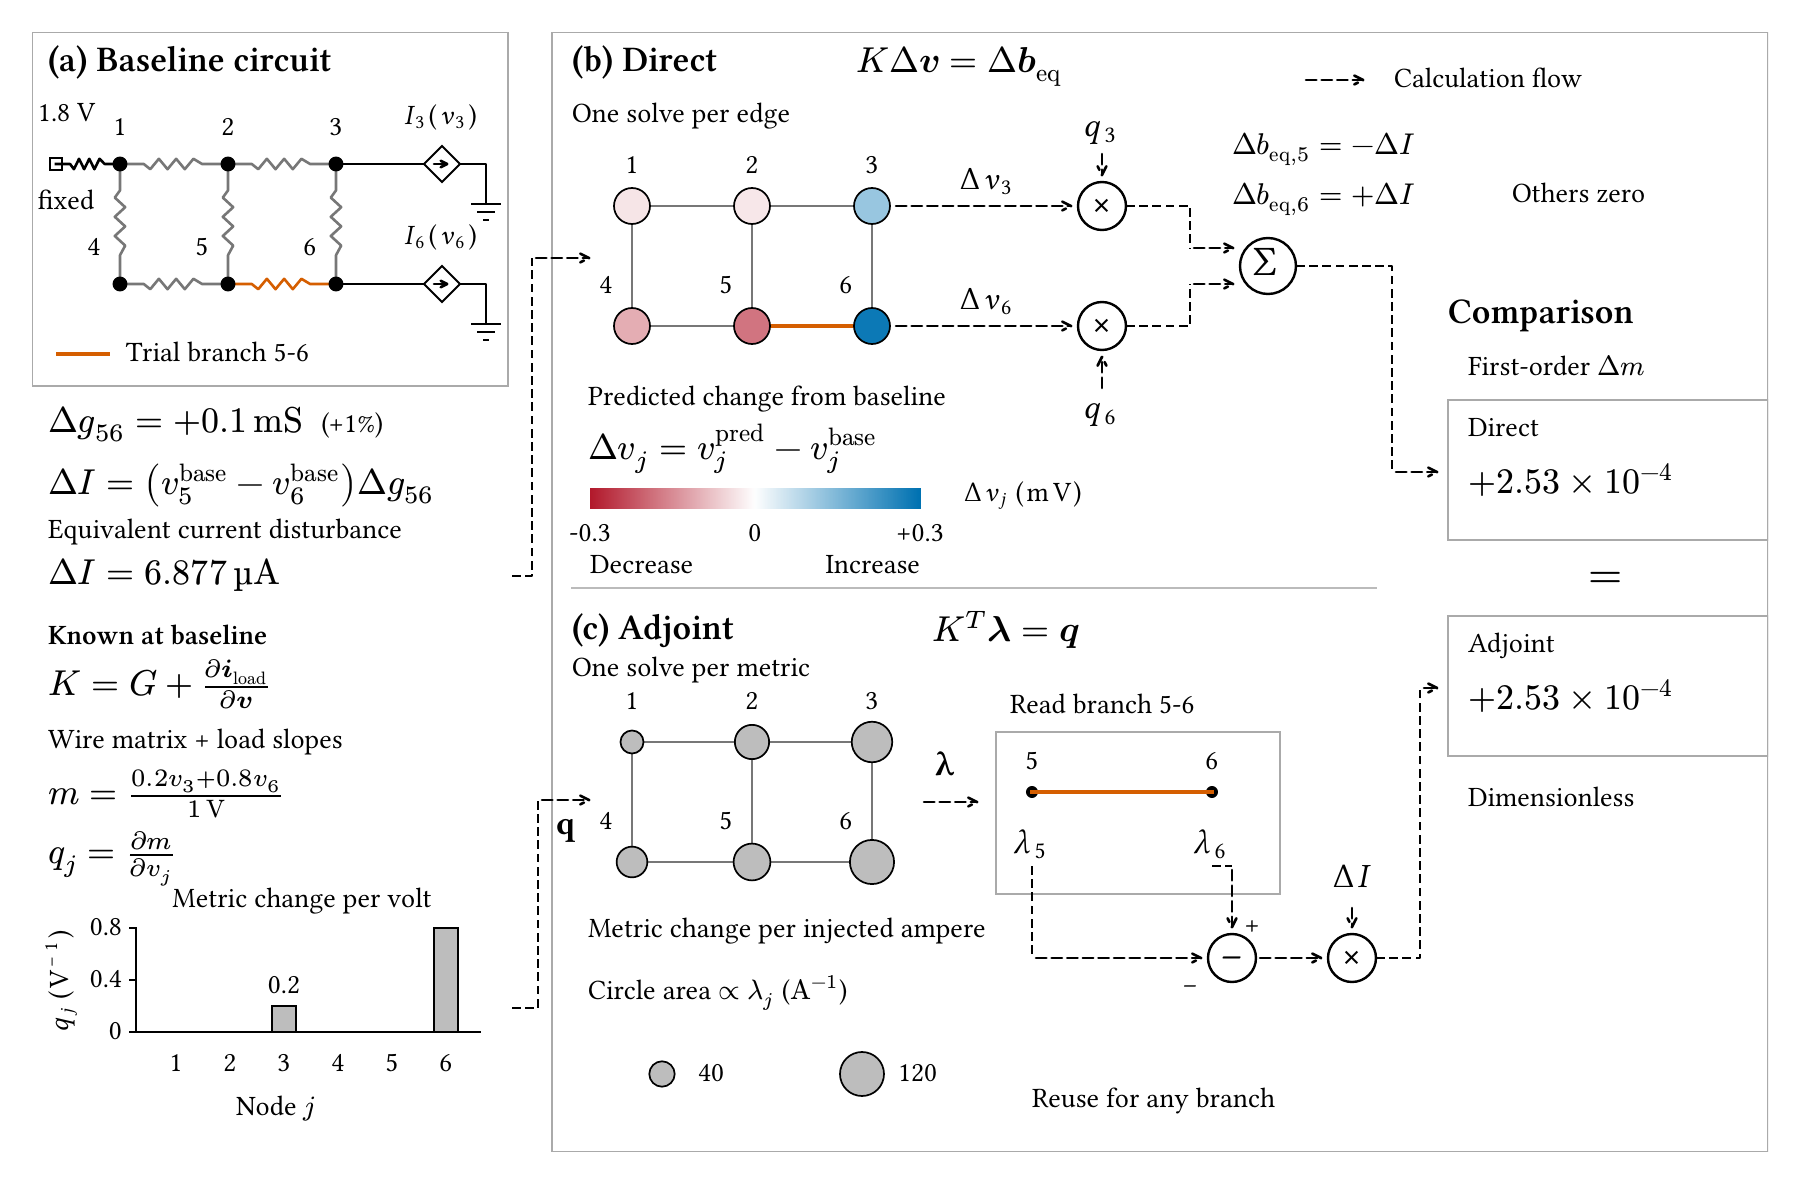

In [9]:
figure("method_adjoint")

*Figure 6. Direct and adjoint sensitivity calculations. Solid lines indicate electrical connections and dashed arrows indicate calculation flow; orange identifies branch 5–6. In (b), equal-size nodes are colored by predicted voltage change from the baseline in mV: blue increases and red decreases. The fixed supply has zero change. In (c), circle area is proportional to the positive adjoint value, in metric units per ampere injected. The endpoint readout calculates the branch response from this map. Node numbers are shared across panels; the square marks the fixed supply.*

#### Electrical interpretation of the adjoint

To interpret the adjoint electrically, suppose a small independent current $\Delta b_i$ were injected at one free node $i$, allowing the connected network and devices to respond. From the linearized balance $K\Delta\mathbf v=\Delta\mathbf b$, the metric change would be

$$
\Delta m
\approx\mathbf q_m^T\Delta\mathbf v
=\boldsymbol\lambda_m^T\Delta\mathbf b.
$$

For an injection at node $i$, $\Delta m\approx\lambda_{m,i}\Delta b_i$, so $\lambda_{m,i}$ measures the metric response per injected ampere, including propagation through the connected circuit.

For an internal resistor oriented from $a$ to $b$, a conductance change initially transfers an extra $(v_a-v_b)\Delta g_e$ from $a$ to $b$. The equivalent compensating injections have opposite signs at its endpoints.

For a metric without explicit dependence on that resistor, the resulting sensitivity is

$$
\frac{dm}{dg_e}
=-(\lambda_{m,a}-\lambda_{m,b})(v_a-v_b).
$$

The sensitivity is the product of the baseline voltage difference, which sets the initial current disturbance, and the adjoint difference, which weights its effect on the metric. A branch with a large voltage drop can therefore have a small performance sensitivity when its endpoints have similar adjoint values.

If one endpoint is fixed at source voltage $V_s$, only the free-node voltage responds. For a resistor between free node $a$ and that fixed source, the corresponding expression is

$$
\frac{dm}{dg_e}
=-\lambda_{m,a}(v_a-V_s),
$$

This expression assumes no explicit resistor dependence in the metric and includes the changes in both $G$ and $\mathbf b$ at the fixed-voltage boundary.

The measured, assembled and solved quantities are listed together in Table 2. When a DC metric depends on several device currents, its voltage weighting follows by combining their terminal derivatives through the chain rule.

In [10]:
render("operations_table")

Quantity,How it is obtained,Role in the calculation
Geometry and material parameters,"Read the layout, terminal map and pinned technology data",Define the network resistors and fixed boundaries
Baseline voltages and device currents,Solve the connected operating point in ngspice,Establish the bias for measurement and linearization
Metric value m,Apply the declared measurement to the native circuit result,Record the baseline characteristic in its physical units
Device-current derivatives,Query native small-signal terminal responses at the saved bias,Describe how device loading changes with terminal voltage
Current-balance Jacobian K,Assemble network conductances and device derivatives,Relate node-voltage changes to current-imbalance changes
Metric derivative q for a DC metric,Differentiate the measurement using native device derivatives,Weight the voltage changes by their effect on the metric
Adjoint vector λ for a DC metric,Solve Kᵀ λ = q,Combine electrical propagation with the selected metric response
Device AC admittance and bias derivatives,Native terminal queries at each frequency; central DC bias perturbations,Describe the frequency response and its dependence on terminal bias
AC adjoint ψ,Solve Aᵀ ψ = c at the measurement frequency,Evaluate direct wire sensitivity and the bias-weighting vector qℓ
DC bias adjoint for an AC metric,Solve Kᵀ λℓ = qℓ,Include the operating-point shift in the AC response derivative


*Table 2. Sources and roles of the numerical quantities, including the DC derivation and the AC calculations used for gain and unity frequency.*

#### Extending the response calculation to AC metrics

For the amplifier metrics, the local response must include the direct resistance change and the device-admittance changes caused by the DC bias shift.

At each measurement frequency, a unit AC excitation at one terminal produces a column of current responses with the other terminal excitations set to zero. Repeating this procedure across the terminals gives the complex device admittance matrix. Its dependence on bias can be obtained from the same queries at small positive and negative DC terminal-voltage shifts, using central differences for the derivatives.

To express this calculation, let $\mathbf x(f)$ contain the free-node AC voltages at frequency $f$ under a unit input excitation. The assembled small-signal equations are

$$
\mathcal A(f)\mathbf x(f)=\mathbf s(f),
\qquad
\mathcal A(f)=G+\mathcal Y_d(f)+j2\pi f C_L.
$$

In this assembly, the interconnect conductance matrix $G$ is combined with the native device admittance $\mathcal Y_d$ at the mapped terminals and the declared load capacitances $C_L$. Contributions from the imposed AC sources are collected in $\mathbf s$, with $j^2=-1$ and intrinsic capacitance already included in the device admittance. Selecting the output voltage or voltage difference through $\mathbf c$ gives the complex voltage ratio $H(f)=\mathbf c^T\mathbf x(f)$ for the unit input.

The frequency-domain adjoint is obtained from

$$
\mathcal A(f)^T\boldsymbol\psi(f)=\mathbf c.
$$

For the intermediate response $\ell=\ln|H|$, a small change in the linear AC system gives

$$
d\ell
=\operatorname{Re}\left[
\frac{\boldsymbol\psi^T(d\mathbf s-d\mathcal A\,\mathbf x)}{H}
\right].
$$

The ordinary complex transpose gives the transfer derivative, whose real part yields the logarithmic amplitude change. Both $d\mathbf s$ and $d\mathcal A$ contribute when a changed resistor meets a fixed AC boundary.

With the wire parameters held fixed, the bias-dependent part follows by differentiating the device admittance with respect to DC voltage $v_i$:

$$
(q_\ell)_i
=-\operatorname{Re}\left[
\frac{\boldsymbol\psi^T
(\partial\mathcal Y_d/\partial v_i)\mathbf x}{H}
\right].
$$

With terminal-bias changes weighted by their effect on the AC response, solving $K^T\boldsymbol\lambda_\ell=\mathbf q_\ell$ propagates the sensitivity through the connected DC network:

$$
\frac{d\ell}{dR_e}
=
\left.\frac{\partial\ell}{\partial R_e}\right|_{\mathbf v}
-\boldsymbol\lambda_\ell^T\frac{\partial F}{\partial R_e}.
$$

The first term is the direct wire contribution and the second is the bias contribution, shown separately in Figure 7.

The measurement definition converts the amplitude derivative into the chosen metric. For gain in decibels, $G_{\mathrm{dB}}=20\log_{10}|H|$, the conversion factor is $20/\ln 10$. For a locally smooth descending unity crossing $f_u$, implicit differentiation of $\ln|H(f_u)|=0$ gives

$$
\frac{dG_{\mathrm{dB}}}{dR_e}
=\frac{20}{\ln 10}\frac{d\ell}{dR_e},
\qquad
\frac{df_u}{dR_e}
=-\frac{f_u}{s_f}
\left.\frac{d\ell}{dR_e}\right|_{f_u},
\qquad
s_f=\left.\frac{\partial\ln|H|}{\partial\ln f}\right|_{f_u}.
$$

The gain derivative is evaluated at its measurement frequency, and $s_f$ is the baseline slope at the selected unity crossing. The crossing must have a nonzero slope and remain identifiable under a small perturbation.

Figure 7 applies these derivatives to the common-source return and compares their summed prediction with the full simulation of a 4 µm² widening.

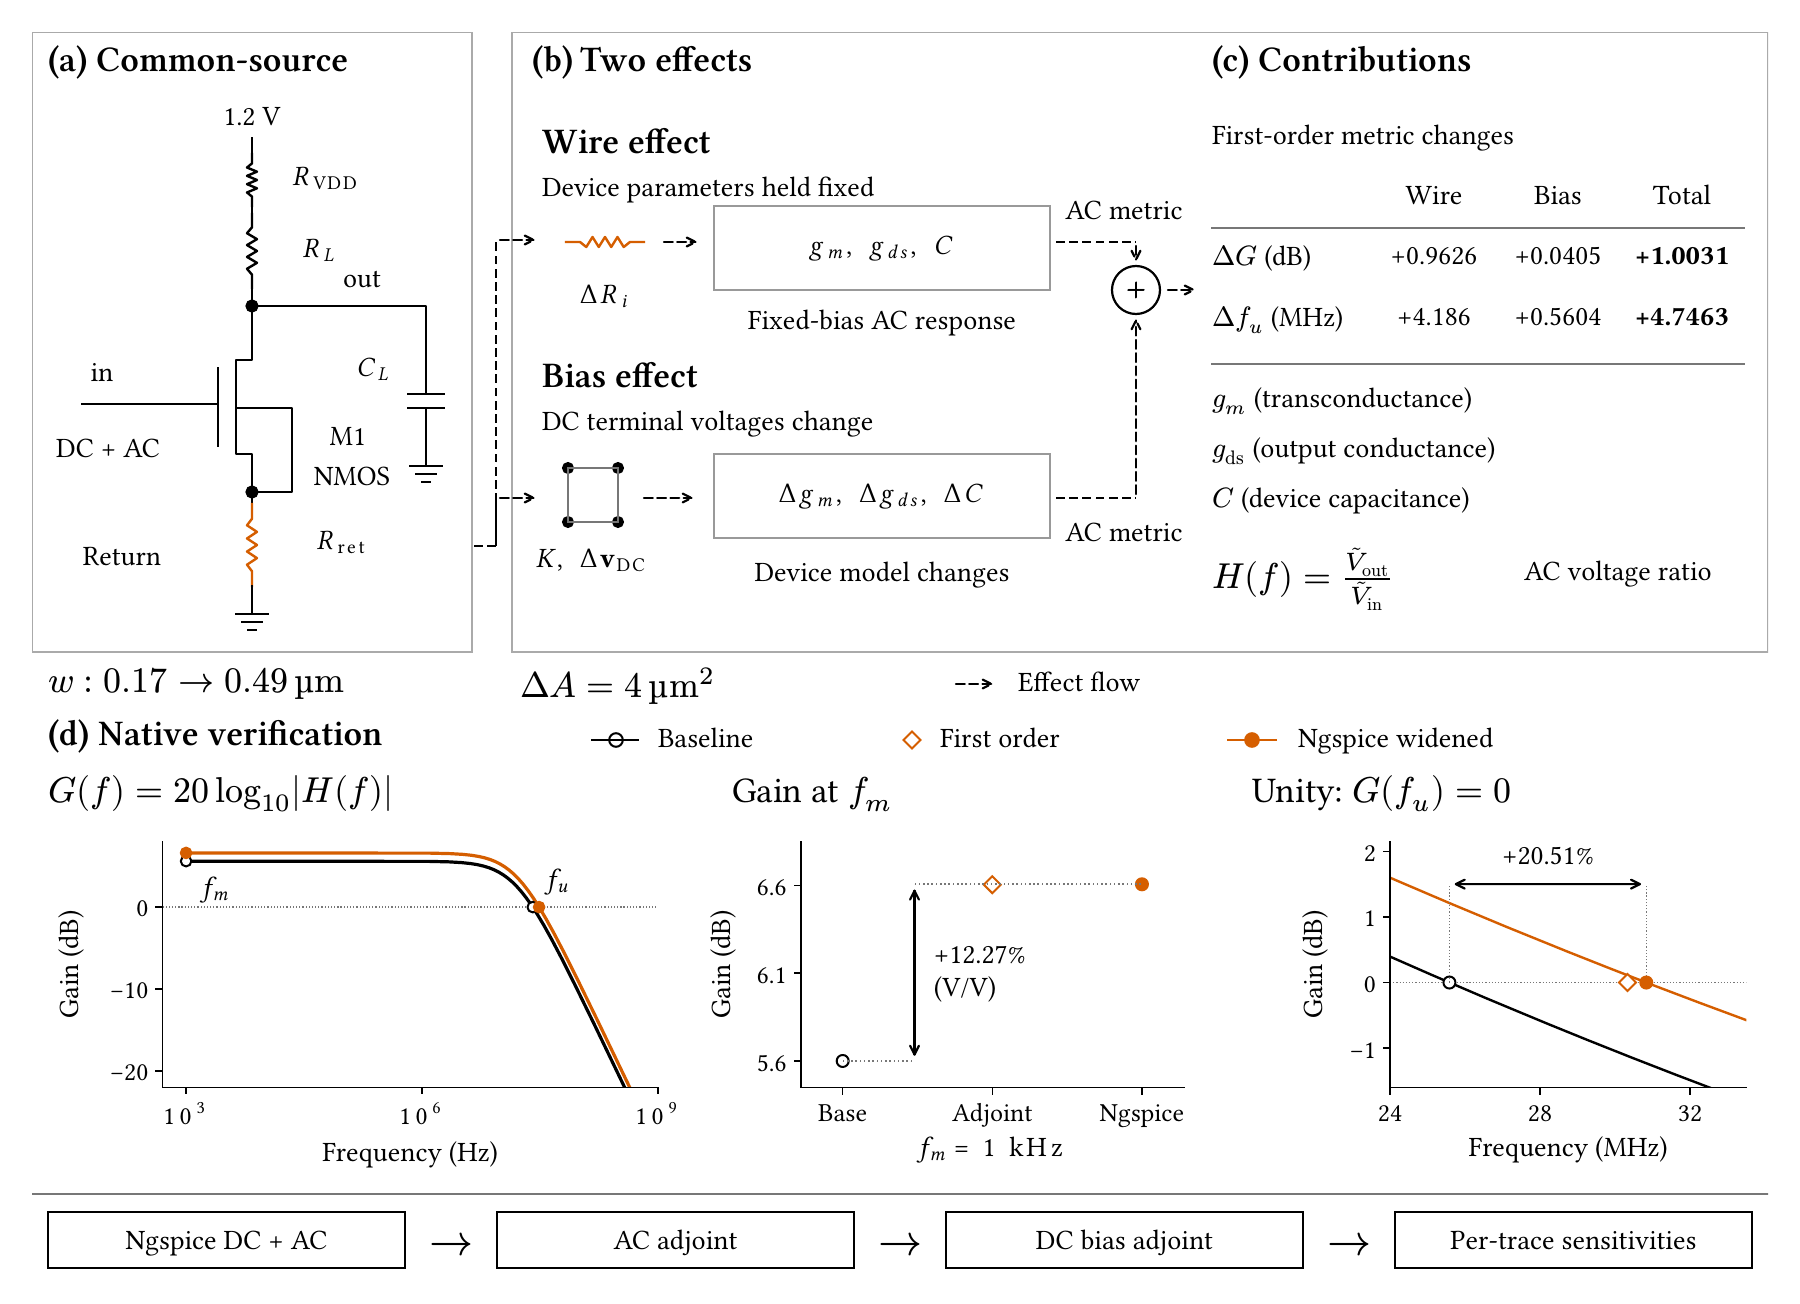

In [11]:
figure("method_ac_paths")

*Figure 7. AC sensitivity for a 4 µm² common-source return widening. Panel (a) identifies the circuit with its 1 pF load; (b) separates the wire and bias paths; (c) gives their signed first-order contributions. In (d), $H$ is the AC voltage ratio, $G$ is its magnitude in dB, $f_m=1$ kHz is the gain measurement frequency, and $f_u$ is the descending 0 dB crossing. Black/open circles show the baseline, orange/filled circles show the widened ngspice result, and open diamonds show the adjoint prediction. Native percentage changes use linear gain and frequency; the inset resolves the crossing.*

### 3.5 Constructing and comparing widening proposals

A widening proposal translates per-resistor sensitivities into a physical modification with a measurable area cost.

A *span* is a continuous straight trace section over which a width change is proposed. It can contain many electrical mesh cells, so mesh refinement can change its resistor representation without changing the span geometry.

#### Discovering the eligible straight spans

Following a permitted supply or return across several layers requires the connected conductor regions to be associated with their schematic nets through the electrical connectivity map. The geometric search is restricted to the permitted conductor layers and excludes protected device-instance bounds, contact and via footprints, external pin patches and additional exclusion boxes.

A sweep through the polygon boundary coordinates in each routing direction divides the remaining geometry into rectangular sections. Wherever neighboring sections have equal cross-sections, they can be joined into a constant-width straight run ending at a width change, bend, junction or protected region. Both ends are shortened by the configured clearance before applying the minimum-length and aspect-ratio conditions.

Each remaining span is recorded by net, layer, centerline, endpoints and original width, allowing every permitted width increment to be applied by moving its side edges outward equally on the layout database grid. Measuring the polygon difference gives the actual added area, against which the budget is checked. Candidates that add no conductor, exceed the budget, enter protected geometry or touch another net are rejected at this stage; those selected for refinement then undergo native DRC/LVS against the applicable process rules.

Figure 8 shows the constant-width trace, fixed landing and symmetric added strips for a reference widening.

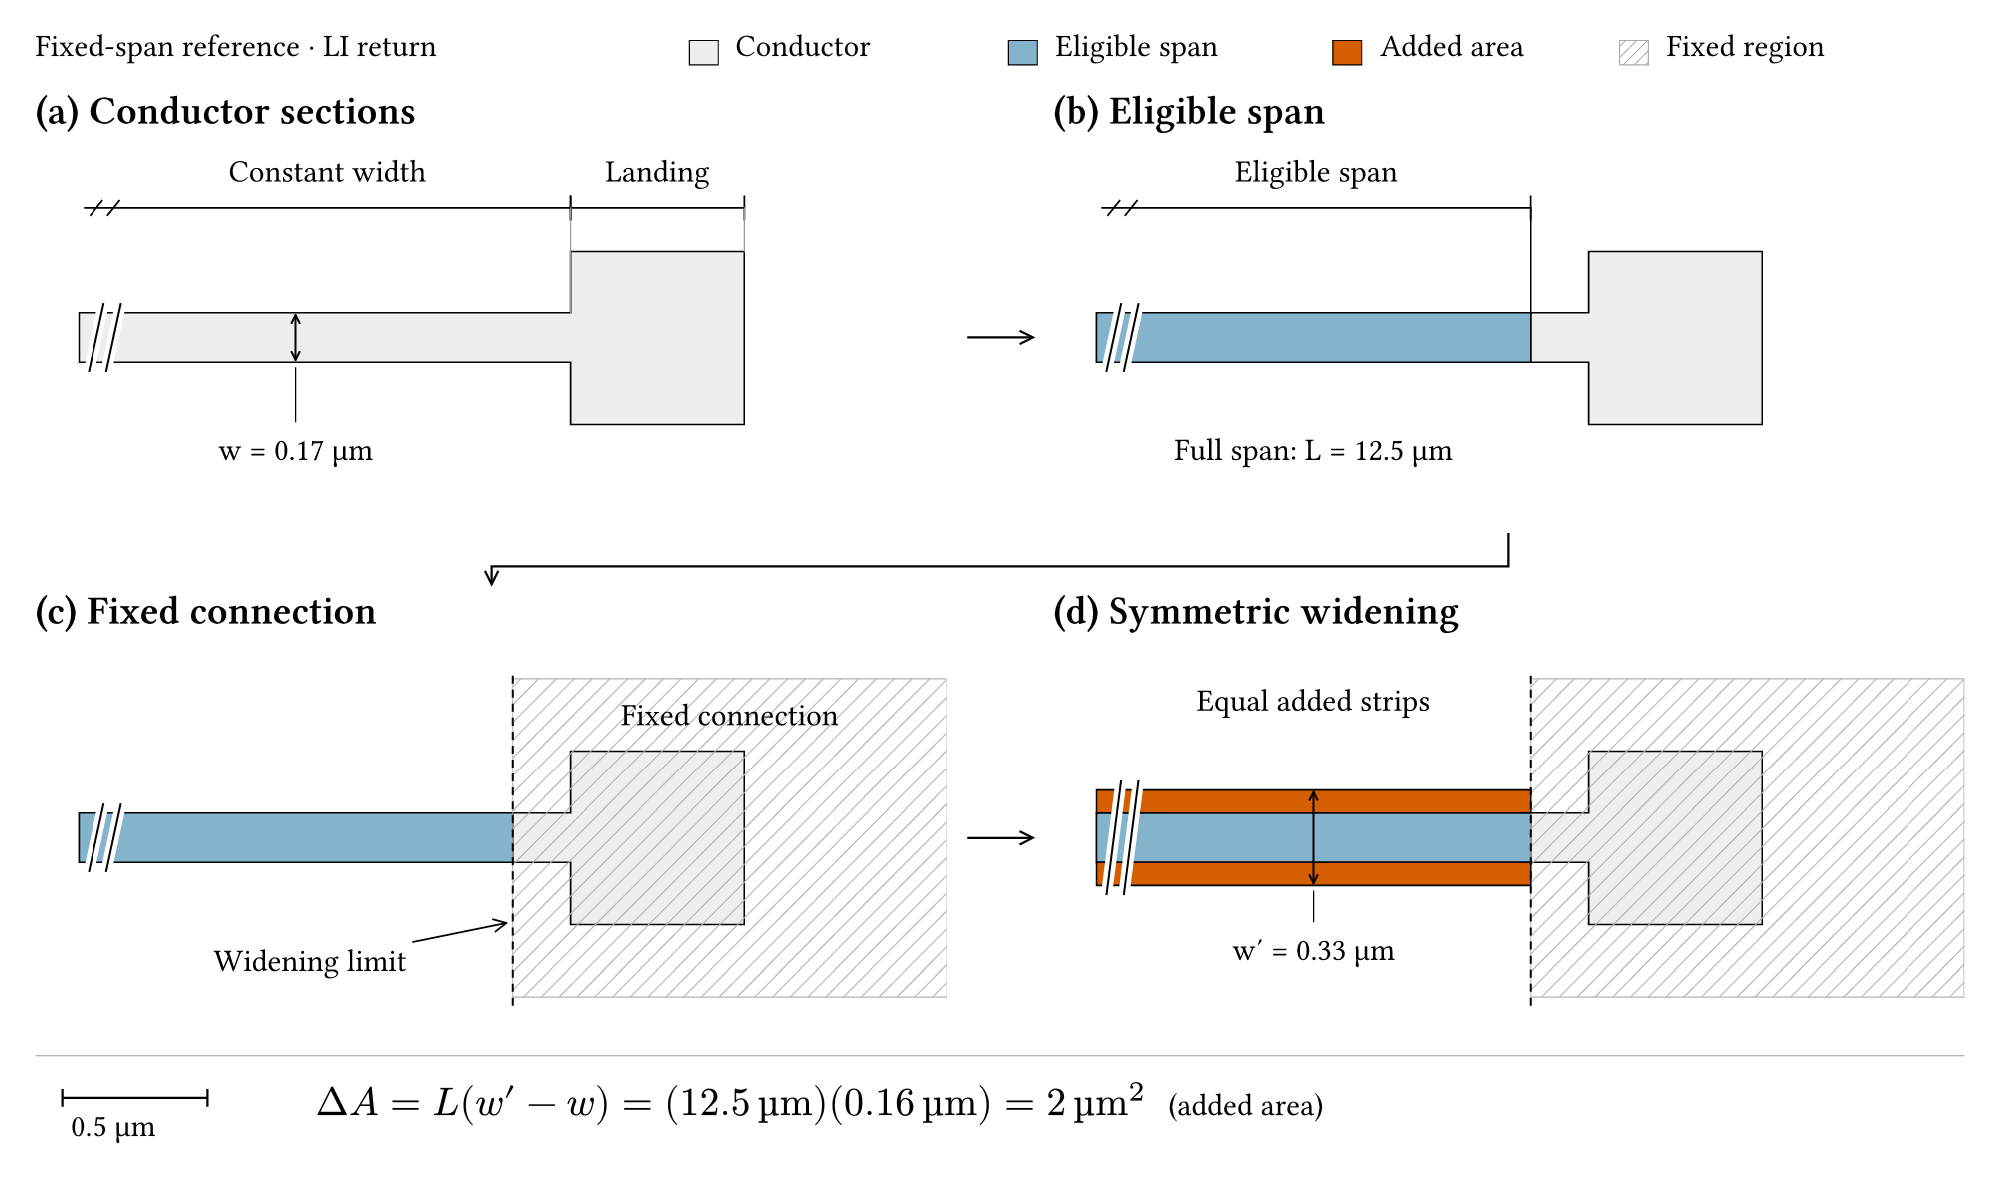

In [12]:
figure("method_spans")

*Figure 8. Geometry of the common-source LI reference widening. Panels share a scale, with break marks indicating continuation. Brackets identify constant-width sections, blue marks the eligible span, and hatching marks the fixed connection beyond the dashed widening limit. Equal orange strips increase the width from 0.17 to 0.33 µm over the full 12.5 µm span, adding 2 µm².*

#### Translating added width into an electrical estimate

For a uniform straight trace of length $L$, width $w$ and sheet resistance $R_\square$, its resistance is $R=R_\square L/w$. Widening it to $w'$ at the same length gives

$$
\frac{R'}{R}=\frac{w}{w'},
\qquad
\Delta R=R\left(\frac{w}{w'}-1\right).
$$

Primed quantities describe the widened trace; $w'>w$ gives a negative longitudinal resistance change.

If a longitudinal resistor represents a path only partly covered by the widening, the affected length fraction $f_e$ is included:

$$
\Delta R_{e,a}\approx
R_e f_e\left(\frac{w}{w'}-1\right),
\qquad 0\leq f_e\leq 1.
$$

Here $a$ identifies the candidate and $f_e$ is the fraction of the baseline resistor's center-to-center path covered by the span. This approximation excludes end spreading and transverse redistribution, which enter through candidate remeshing in Section 3.6.

The conductance sensitivity is converted to resistance coordinates by the chain rule,

$$
\frac{dm}{dR_e}=-g_e^2\frac{dm}{dg_e},
$$

because $g_e=1/R_e$. The estimated metric change for the action is then

$$
\widehat{\Delta m}_a
=\sum_{e\in\mathcal E_a}
\frac{dm}{dR_e}\Delta R_{e,a},
\qquad
\widehat m_a=m_0+\widehat{\Delta m}_a.
$$

The set $\mathcal E_a$ contains the affected baseline resistors, $m_0$ is the baseline metric, and a hat denotes a prediction.

#### Applying area limits and performance requirements

For an isolated rectangular span, $\Delta A_a=L(w'-w)$ gives the added area. Measuring the polygon difference from the baseline conductor also accounts for overlap with existing shapes.

For an area budget $A_{\mathrm{budget}}$, a feasible proposal satisfies

$$
\Delta A_a\leq A_{\mathrm{budget}}.
$$

Performance limits are evaluated at the predicted metric values as a separate acceptance condition. Depending on the experiment, these can specify a minimum or maximum value, a bound on target error, or a requirement that an individual error should not increase relative to the baseline.

To compare several target errors through a single objective, their deviations are scaled to the configured requirements and combined as

$$
J(\mathbf m)=\frac12\sum_k w_k
\left(\frac{m_k-t_k}{s_k}\right)^2.
$$

For metric vector $\mathbf m$, each target $t_k$ is paired with a positive scale $s_k$ in metric units and a nonnegative dimensionless weight $w_k$. Scaling establishes the significant error range; weighting controls its contribution to $J$, so a reduction corresponds to improvement.

The predicted benefit and benefit per added area are

$$
\widehat B_a=J(\mathbf m_0)-J(\widehat{\mathbf m}_a),
\qquad
\widehat\eta_a=\frac{\widehat B_a}{\Delta A_a}.
$$

The baseline measurements are $\mathbf m_0$, and $\widehat{\mathbf m}_a$ contains the predicted candidate metrics.

Eligible individual alternatives are ranked by total predicted benefit within the budget, with benefit per area reported as an efficiency measure. The comparison evaluates individual modifications against the unchanged design; simultaneous combinations require a separate search.

Figure 9 uses two illustrative metrics with targets of one, baseline values of 0.88 and 0.80, unit scales and equal weights, giving $J_0=0.0272$. For the constraint plot, each absolute target error is divided by its baseline error: zero denotes the target and one denotes the maximum allowed error. The objective uses the original metric values, with $\widehat J_a=J(\widehat{\mathbf m}_a)$.

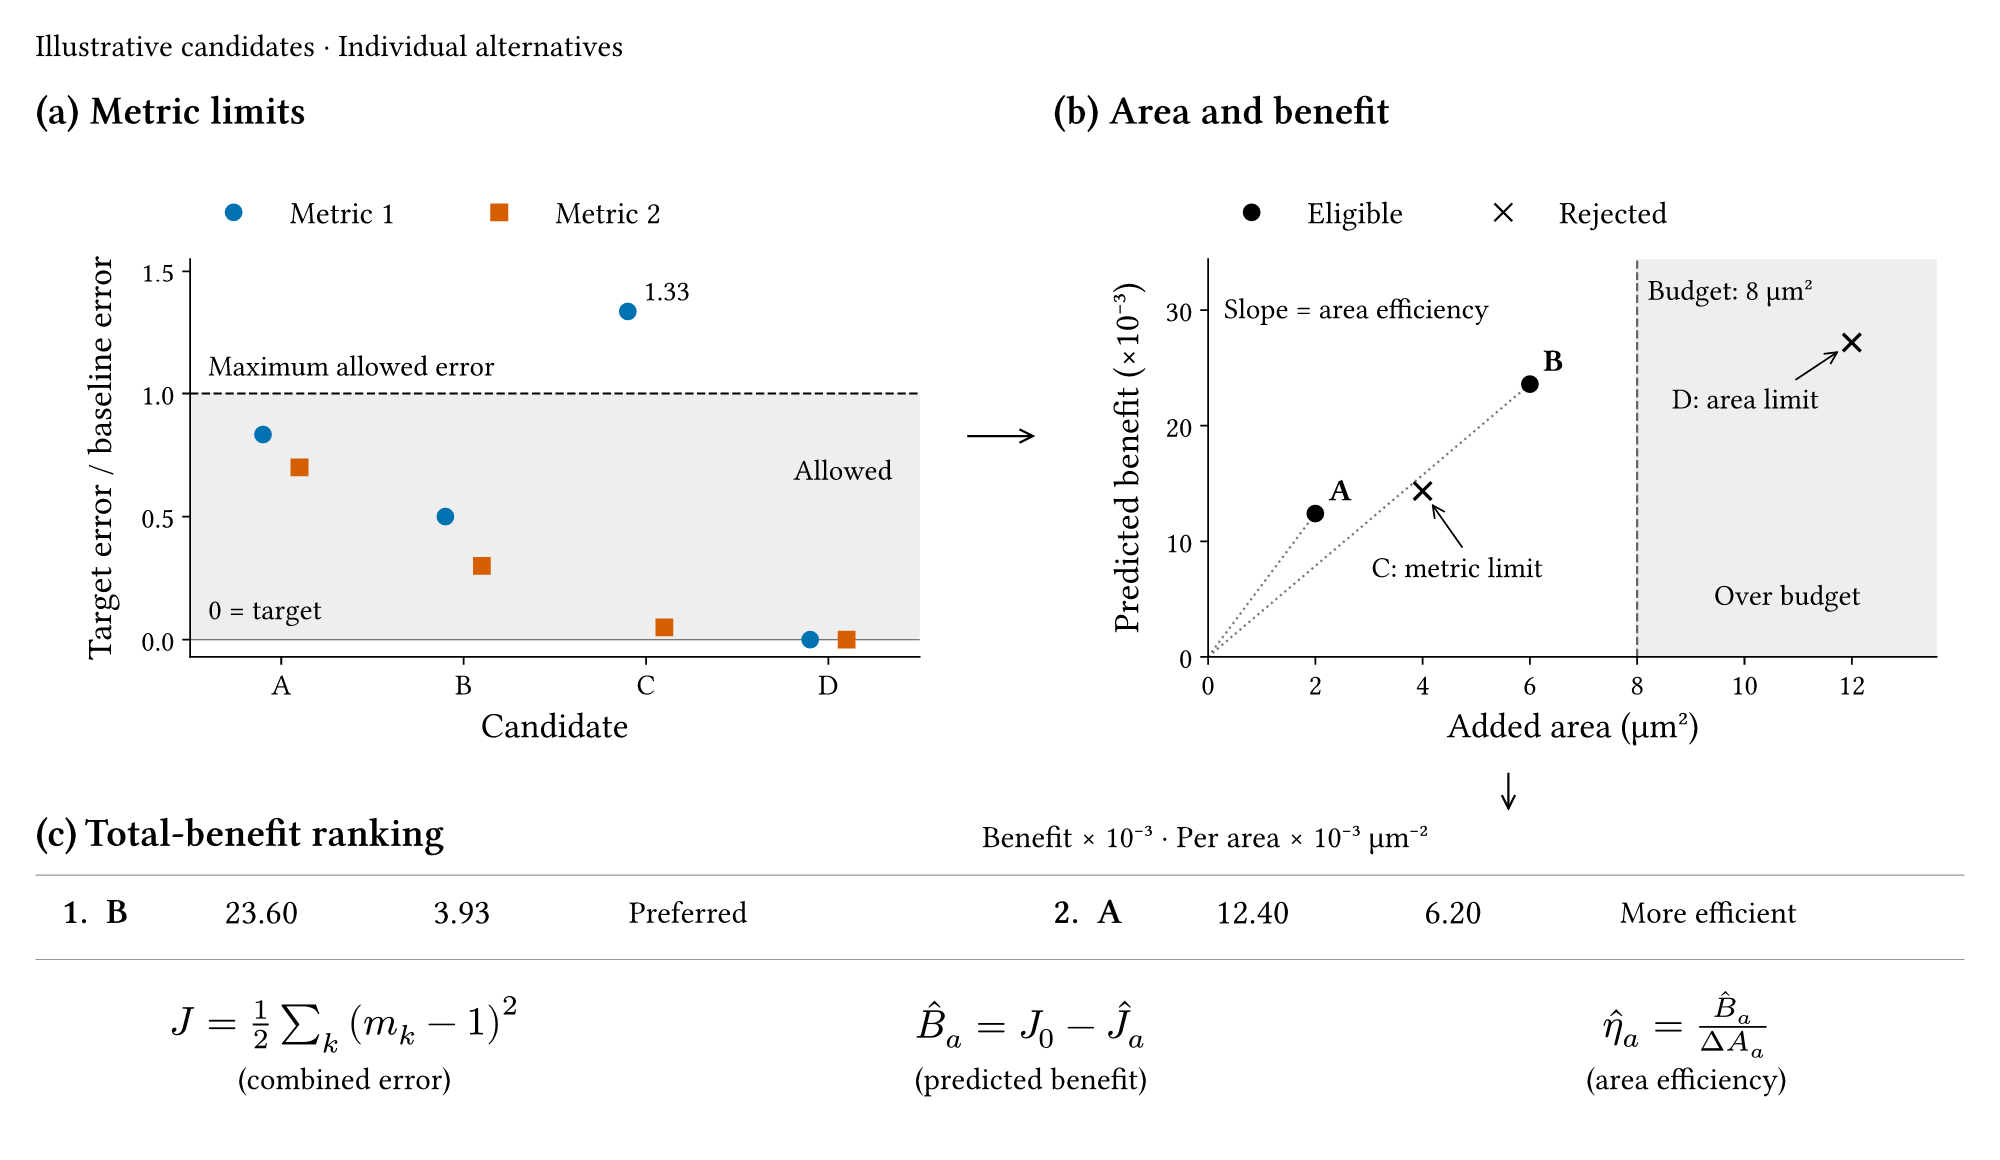

In [13]:
figure("method_selection")

*Figure 9. Screening and total-benefit ranking. Blue circles and orange squares identify the metrics in (a); C exceeds the error limit for Metric 1. In (b), filled circles are eligible and crosses are rejected; D exceeds the 8 µm² budget. Dotted-ray slopes give benefit per area. B ranks first by total benefit, and A has greater area efficiency. These candidates are illustrative.*

### 3.6 Predicting finite changes and verifying the modified circuit

A finite widening can shift device-current slopes and redistribute current enough to limit the accuracy of a baseline derivative. The shared predictor therefore remeshes the DRC/LVS-checked candidate and estimates its new bias and AC response before full simulation.

Internal wire nodes contribute only linear resistor equations, so their elimination reduces the size of the candidate prediction problem. Device terminals, free output nodes and load connections remain as *port nodes*. With fixed-source contributions included in the right-hand side, the candidate equations can be partitioned into port voltages $\mathbf u$ and internal voltages $\mathbf z$:

$$
\begin{bmatrix}G_{pp}&G_{pz}\\G_{zp}&G_{zz}\end{bmatrix}
\begin{bmatrix}\mathbf u\\\mathbf z\end{bmatrix}
+
\begin{bmatrix}\mathbf i(\mathbf u)\\\mathbf 0\end{bmatrix}
=
\begin{bmatrix}\mathbf b_p\\\mathbf b_z\end{bmatrix}.
$$

The subscripts $p$ and $z$ identify port and internal nodes. Eliminating $\mathbf z$ gives

$$
S_a\mathbf u+\mathbf i(\mathbf u)=\mathbf b_a,
\qquad
S_a=G_{pp}-G_{pz}G_{zz}^{-1}G_{zp},
\qquad
\mathbf b_a=\mathbf b_p-G_{pz}G_{zz}^{-1}\mathbf b_z.
$$

Evaluating the elimination through linear solves for the internal nodes gives the candidate's reduced wire conductance matrix $S_a$ and source vector $\mathbf b_a$. The terminal relation remains equal to that of the full linear resistor network under this Schur-complement or Kron reduction <a href="#ref-dorfler2013">[9]</a>.

Figure 10(a) uses the series path $1.8\,\mathrm V\rightarrow R_1\rightarrow a\rightarrow R_2\rightarrow b$, with $g_1=1/R_1=15\,\mathrm{mS}$ and $g_2=1/R_2=10\,\mathrm{mS}$. Loads to ground draw $I_a=1\,\mathrm{mS}(v_a-1.2\,\mathrm V)$ and $I_b=2\,\mathrm{mS}(v_b-1.1\,\mathrm V)$. The metric is $m=(0.2v_a+0.8v_b)/(1\,\mathrm V)$, with baseline $m_0=1.62$. Varying only $R_2$ gives the first-order prediction

$$
\Delta m_{\mathrm{pred}}
=\left.\frac{\partial m}{\partial R_2}\right|_0
 (R_2-R_{2,0}).
$$

Reducing $R_2$ from $100\,\Omega$ to $25\,\Omega$ gives a predicted change of $0.043868$, compared with $0.049468$ from the complete network solution. The error is therefore $11.32\%$ of the solved change, using $\lvert\Delta m_{\mathrm{pred}}-\Delta m_{\mathrm{solved}}\rvert/\lvert\Delta m_{\mathrm{solved}}\rvert$. The response curves even with these affine current laws because the circuit solution depends nonlinearly on the resistance parameter.

Figure 10(b) reduces seventeen $1\,\mathrm{k}\Omega$ resistors on a twelve-node grid to six equivalent branches between the four corner ports. Native ngspice comparisons applied four basis excitations—one port at $1\,\mathrm V$ and the others at zero—and the displayed voltage vector. These check every column of the terminal conductance matrix; the largest full-versus-reduced current difference was $3.25\times10^{-19}\,\mathrm A$.

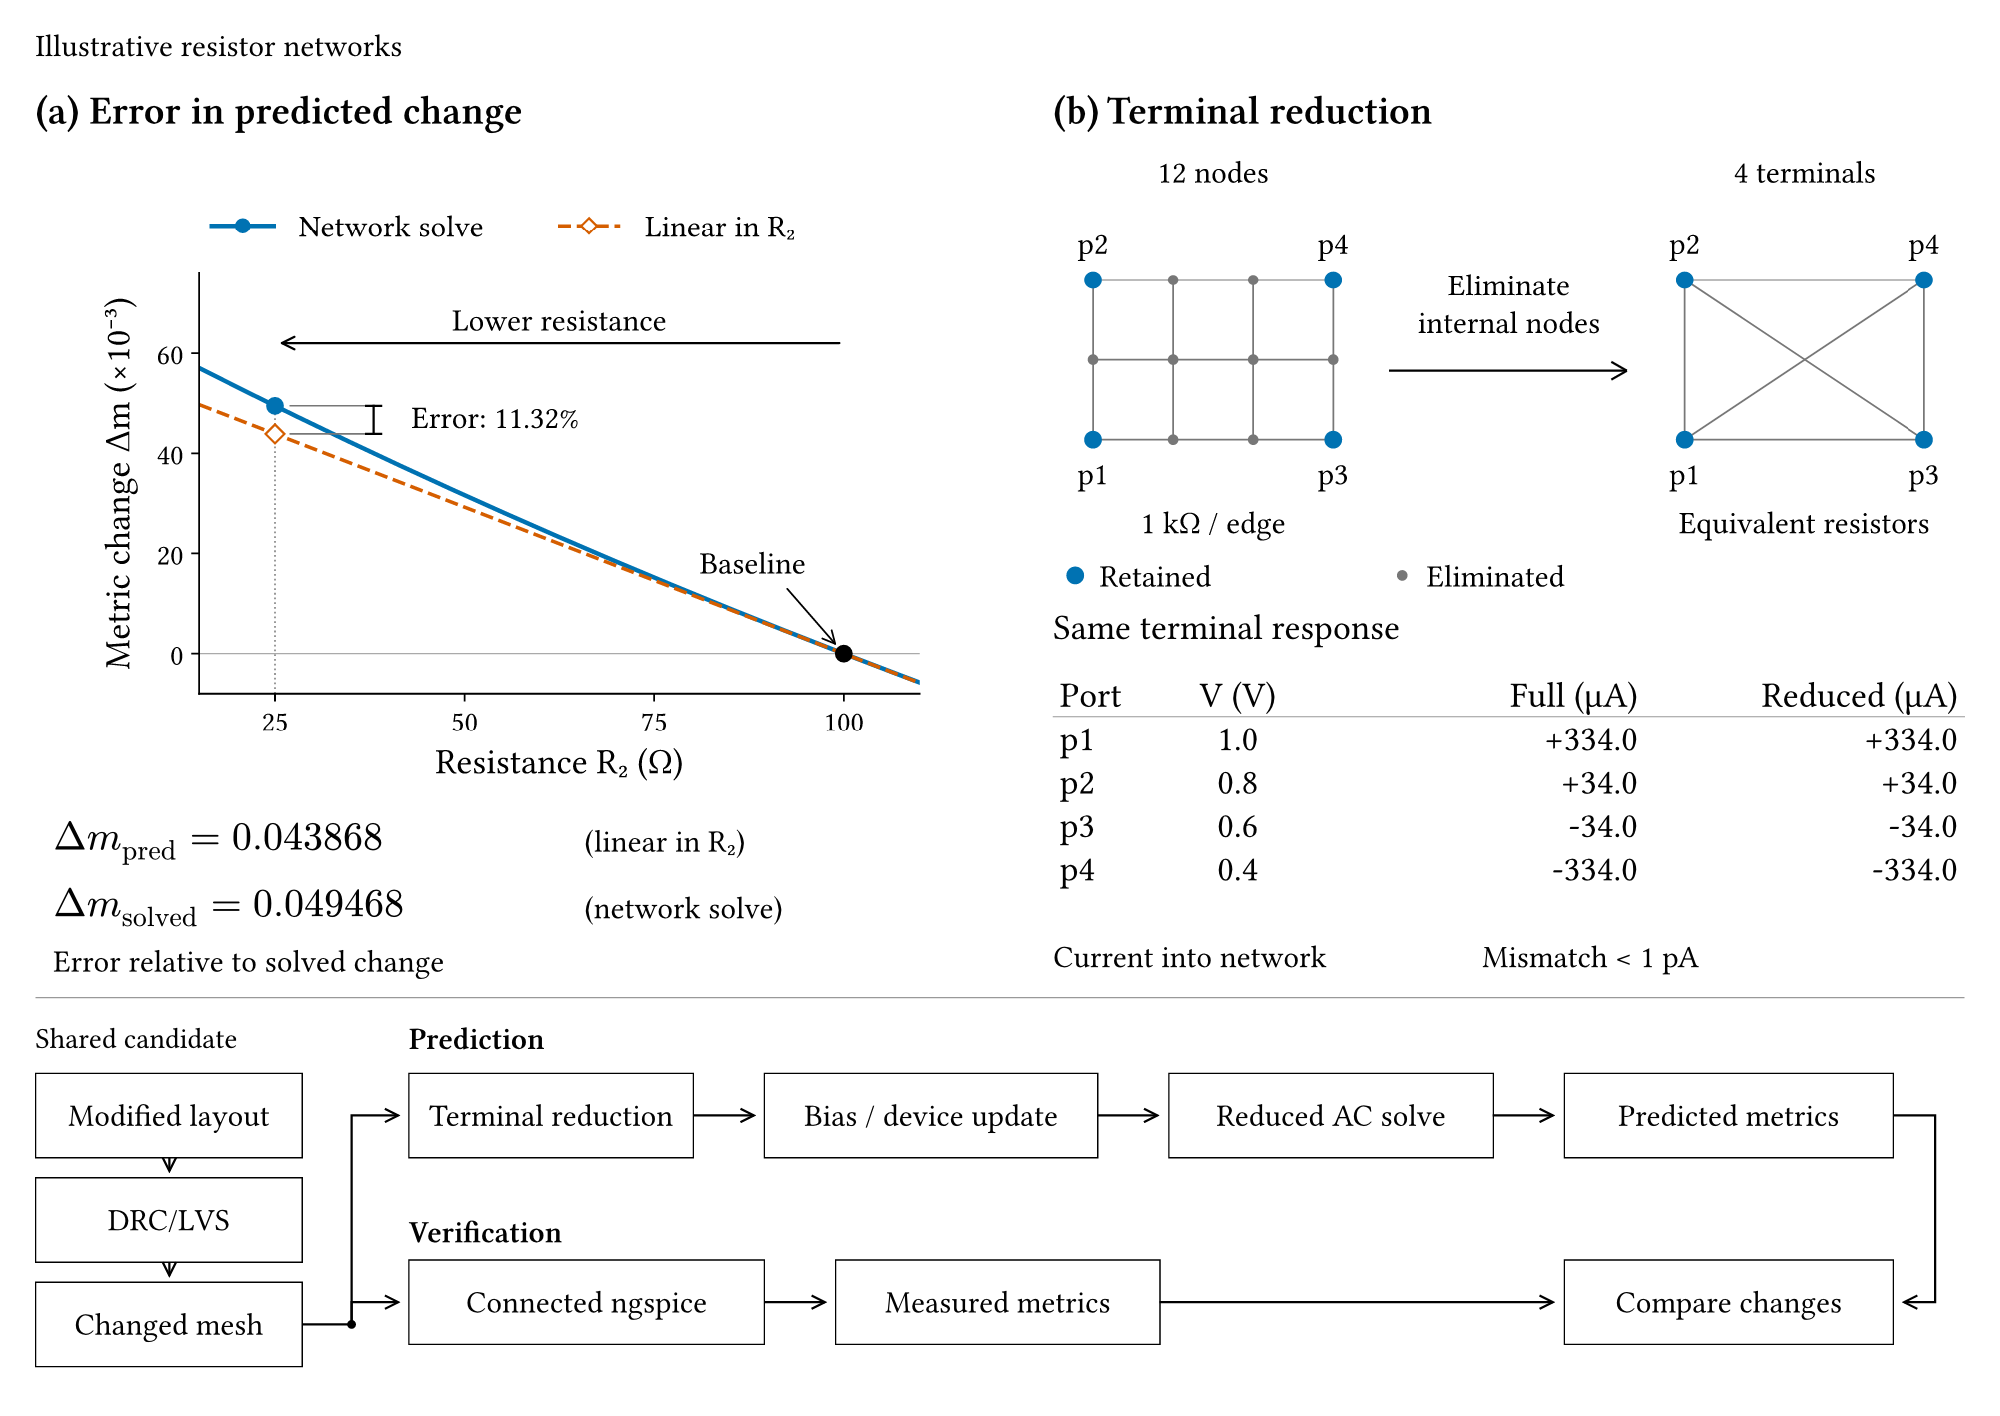

In [14]:
figure("method_finite_change")

*Figure 10. Finite prediction and reduction. In (a), blue shows the solved metric change, and orange shows the first-order prediction in resistance; the bracket marks their difference at $25\,\Omega$. In (b), blue nodes are ports and gray nodes are eliminated. Edges are resistors, with no junction at the diagonal crossing; tabulated currents enter the network. The lower paths share a DRC/LVS-checked candidate mesh and compare predicted with measured changes.*

#### Predicting the candidate bias and frequency response

At the candidate's port nodes, let $\mathbf u_0$ and $\mathbf i_0$ denote baseline voltages and device currents, and let $Y_{\mathrm{DC},0}$ be the device-current Jacobian. Connections with no device contribute zero current and derivative entries. Substituting $\mathbf i(\mathbf u_0+\Delta\mathbf u_a)\approx\mathbf i_0+Y_{\mathrm{DC},0}\Delta\mathbf u_a$ into the reduced balance gives

$$
(S_a+Y_{\mathrm{DC},0})\Delta\mathbf u_a
=
\mathbf b_a-S_a\mathbf u_0-\mathbf i_0,
\qquad
\widehat{\mathbf u}_a=\mathbf u_0+\Delta\mathbf u_a.
$$

Placing the baseline state on the changed network produces the current imbalance on the right-hand side. Using the candidate conductance $S_a$ with the baseline device-current slopes, one linear solve estimates the resulting bias shift.

At the predicted terminal voltages, the device currents are queried for the reduced DC residual check and the complex admittances are refreshed for the AC calculation with the declared load capacitances. Gain can then be evaluated at its configured frequency. Locating the unity crossing requires a frequency search, initially based on a linear interpolation in frequency between admittance queries at a low frequency and the baseline crossing. The first descending crossing of the reduced circuit is selected.

A native query at the predicted crossing checks the unit-magnitude condition. If its residual exceeds tolerance, that frequency becomes the next interpolation anchor and the crossing search is repeated. Excessive DC current-balance or crossing residuals flag an estimate for further verification.

The single bias update and frequency interpolation introduce approximation error. Their cost includes native device queries and reduced solves, in addition to candidate remeshing and sparse elimination.

#### Verifying the predicted modification

Verification requires a complete ngspice simulation of the candidate mesh and connected devices under the baseline external conditions. The predicted improvements can then be compared with measured changes, and the feasible verified candidate with the largest positive measured objective benefit is selected. If none improves the objective, the original design remains the result.

Different comparisons address the derivative, the geometry change and the discretization. Central resistor perturbations on a fixed mesh check the local derivative; physical widenings assess the mapping from geometry to performance. Selected finer-mesh comparisons keep geometry and contact footprints fixed to isolate discretization effects. Error limits are stated for each experiment, including absolute tolerances for very small metric changes.

<a id="implementation"></a>
## 4 Implementation

The same numerical and geometric functions are used for each supported circuit, with the project configuration carried through the stages in Section 3. The excerpts below follow the calculation from network construction and connected simulation to sensitivity and candidate verification, with spacing and line breaks adjusted for readability. The surrounding initialization, file handling and diagnostic checks are available through the source links.

Python 3.12, NumPy <a href="#ref-numpy2020">[11]</a> and SciPy <a href="#ref-scipy2020">[10]</a> provide the array operations, sparse factorization and linear solves needed for the numerical calculations. Geometry processing and PDK DRC/LVS are performed in KLayout <a href="#ref-klayout">[12]</a>, with SKY130 device simulation in ngspice <a href="#ref-ngspice">[7]</a>, schematic export through Xschem <a href="#ref-xschem">[13]</a> and plotting through Matplotlib. Interactive result controls use ipywidgets in the optional notebook environment. In the reference Ubuntu 24.04 WSL 2 environment, the Python dependencies are installed from the uv lockfile; native-tool and PDK versions are specified in the configuration files.

### 4.1 Project inputs and execution

The schematic and layout must describe the same circuit, with the design subcircuit matched to the layout cell and pin labels through a JSON configuration. Device models, sources, bias, load and operating conditions come from the supplied Xschem testbench or exported SPICE netlist, accompanied by its GDS or OASIS layout. Measurements and permitted geometry changes are specified in the same configuration, with paths resolved relative to the JSON file.

Available options and examples are documented under `_help` in the [example configuration](../examples/project.example.json). The excerpt below sets a gain requirement and an added-area budget; the complete example also includes unity-gain frequency and the design inputs.

```json
{
  "metrics": {
    "gain_dB": {
      "measurement": "gain_dB", "frequency_Hz": 1000,
      "target": 7.2, "scale": 1.0, "weight": 1.0,
      "constraints": {"minimum": 3.0}
    }
  },
  "actions": {
    "nets": ["vdd", "0"], "layers": ["li", "m1"],
    "width_increments_um": [0.01, 0.16, 0.32, 0.48, 0.8],
    "budget_um2": 10
  }
}
```

The target and normalization scale determine how each metric enters the objective, with an independent limit for acceptance. Changing the action settings restricts the geometric search, and each total width increment is divided equally between both trace edges. These settings are interpreted by the same calculations for both amplifier examples.

The current input profile is limited to flat SKY130 circuits with the implemented NMOS, PMOS and high-resistance poly-resistor geometries, one transistor finger and multiplicity one. Manhattan routing and numeric device dimensions and source values allow these inputs to be processed by [read_design](../perfpdn/design.py), with schematic devices matched to physical instances through the LVS correspondence. The testbench must have one design instance, ground-referenced voltage sources and constant load capacitors between free nodes or AC-grounded boundaries.

<a id="installation"></a>
<details>
<summary>Environment setup</summary>

Install the native-tool prerequisites, then the KLayout application matching the Python binding:

```bash
sudo apt-get update
sudo apt-get install git build-essential libreadline-dev autoconf automake libtool \
  curl ca-certificates python3-venv xschem libxcb-cursor0 libopengl0
curl --fail --location \
  https://www.klayout.org/downloads/Ubuntu-24/klayout_0.30.12-1_amd64.deb \
  -o /tmp/perfpdn-klayout.deb
printf '%s  %s\n' \
  23480767fec91bc9a15e075a9bd6906ba85cd7fdda8b4040dde4ffc95c26a742 \
  /tmp/perfpdn-klayout.deb | sha256sum --check
sudo apt-get install /tmp/perfpdn-klayout.deb
```

From the project root, create the Python environment and install the pinned PDK and ngspice build:

```bash
uv sync --locked --python /usr/bin/python3
source scripts/env.sh
bash scripts/install_pdk.sh
bash scripts/install_ngspice.sh
uv run --locked python scripts/check_environment.py
```

During setup, the Python dependencies are synchronized and the native-tool paths checked. The ngspice source archive is verified before compilation, and the specified SKY130A build is obtained through Ciel.

</details>

From the project root, run the example with:

```bash
source scripts/env.sh
uv run --locked python scripts/perfpdn.py run examples/project.example.json
```

For fish, source `scripts/env.fish`. Start with `check` for baseline DRC/LVS, use `analyze` to obtain baseline measurements and sensitivities, or continue through candidate prediction and verification with `run`. A saved study can be redrawn with `plot`. To control computational effort, set `refine_count` for the finite-change calculations and `verification_count` for complete simulations; `null` requests all candidates at the corresponding stage.

<details>
<summary>Opening the notebook</summary>

```bash
uv run --locked --extra notebook jupyter lab submission/PerfPDN.ipynb
```

Executing the display cells checks the hashes of the supplied evidence before displaying it. New numerical studies are saved separately under `output/<project>/unified/`.

</details>

### 4.2 Constructing the resistance network

After the conductor regions have been merged with `klayout.db` and divided along the grid from Section 3.1, the occupied cells must be connected without counting a shared face twice. Traversing the grid in a fixed order in [build_network](../perfpdn/mesh.py) makes it sufficient to check the left and lower neighbors, whose node names can be retrieved from `lookup`:

```python
for dx, dy in ((-1, 0), (0, -1)):
    other = lookup.get((layer, ix+dx, iy+dy))
    if other is not None:
        distance = (right-x[ix-1])/2 if dx else (upper-y[iy-1])/2
        face = upper-bottom if dx else right-left
        add_edge(other, name, rho[layer]*distance/face, layer, face*unit)
```

Both the center spacing `distance` and shared-face width `face` are measured in database units, so their ratio can be multiplied directly by the sheet resistance `rho[layer]` to give resistance in ohms. The physical width is still needed for sheet-current calculations and is therefore recorded separately through `face*unit`.

A contact's conductance must be shared between the cells under its footprint. Because the grid axes include the cut boundaries, each overlap area can be calculated from its coordinate intervals and divided by the full cut area:

```python
fraction = (x[ix+1]-x[ix])*(y[iy+1]-y[iy])/box.area()
add_edge(a, b, resistance/fraction, "contact:"+rule)
```

Applying this overlap-area fraction `fraction` from Section 3.1 gives a branch resistance of `resistance/fraction`. Each branch joins its own endpoint potentials, so its current follows from the connected ngspice solution.

The completed edge list can now be assembled into nodal equations. In [assemble](../perfpdn/system.py), each edge becomes a column of the sparse incidence matrix `B`, with signed entries in the rows of its free endpoints:

```python
for k, (a, b, *_) in enumerate(edges):
    for node, sign in ((a, 1), (b, -1)):
        if node in index:
            rows.append(index[node])
            cols.append(k)
            values.append(sign)
B = coo_matrix((values, (rows, cols)),
               shape=(len(names), len(edges))).tocsc()
R = np.array([e[2] for e in edges])
G = (B @ diags(1 / R) @ B.T).tocsc()
```

Multiplication by `diags(1/R)` weights the incidence columns by the conductances corresponding to the branch resistances in `R`, giving `G` the nodal structure from Section 3.2. Fixed-source nodes are excluded from `names`, which puts their voltage contributions in the source vectors. Those contributions must also be updated when a boundary-connected resistor changes.

### 4.3 Obtaining the operating point and device response

Appending the complete edge list to the sources, devices and load capacitors in `base` produces the connected model whose operating point is needed for sensitivity analysis. The native operating-point command in [solve](../perfpdn/circuit.py) then resolves their nonlinear interaction:

```python
base += [f"r{i} {a} {b} {r:.17g}"
         for i, (a, b, r, *_) in enumerate(network["edges"])]
(folder / "base.cir").write_text("\n".join(base) + "\n")
spice(["PerfPDN connected layout circuit", *base,
       ".save all", ".control", "set filetype=ascii",
       "op", "write op.raw all", "quit", ".endc", ".end"], folder)
raw = read_scalar_raw(folder / "op.raw")
```

The deck is executed through `ngspice -b`, called by the [spice](../perfpdn/native.py) helper through `subprocess.run`, with its log and raw results saved. Following the native iteration described in Section 3.2, the converged voltages and terminal currents are read into Python for branch-current, loss and conservation calculations. A solution is accepted only if the largest free-node current residual does not exceed 1 nA and the absolute power residual does not exceed 1 nW.

Resolving small interconnect drops requires care when subtracting node voltages. Each resistively connected component is therefore solved with a constant voltage offset, and branch differences are calculated in these shifted coordinates. Series sources restore the device-terminal voltages and also measure the terminal currents; the offsets are added back when saving the physical node voltages.

At this operating point, sensitivity analysis requires the change in device current with terminal voltage. Clamping the terminals to their solved DC voltages in [terminal_jacobian](../perfpdn/terminals.py) allows these derivatives to be queried through ngspice's `tf` command:

```python
for row in range(len(ports)):
    for col in range(len(ports)):
        deck += [f"tf i(vc_{ports[row]}) vc_{ports[col]}",
                 f"write tf_{row}_{col}.raw all"]
```

For a voltage excitation indexed by column, the current responses are read at the terminals indexed by row. Their signs are reversed to express current into the device. Before the derivatives can be used in the current-balance Jacobian, the clamped DC currents must agree with those of the connected circuit.

The AC queries also need evaluation frequencies, obtained from the connected circuit's voltage-transfer response through [measure](../perfpdn/measure.py). Gain is evaluated at the configured frequency, and the first descending unity crossing is refined with native AC points. These measurements establish the baseline metric values and frequencies for the sensitivity calculation.

At those frequencies, exciting one terminal source with unit AC voltage and keeping the others at zero AC gives a column of the complex admittance `Y`. Repeating this excitation across the terminals in [device_matrices](../perfpdn/devices.py) completes the matrix. Positive and negative terminal-bias offsets set by `voltage_step_V` then allow central differences for `dY`, the admittance derivatives used in Section 3.4.

### 4.4 Calculating metric sensitivities

With the terminal derivatives available, the current-balance Jacobian `K` from Section 3.2 can be assembled by adding their mapped contributions to the wire matrix. In [calibrate](../perfpdn/sensitivity.py), `device_matrix` places those derivatives at the corresponding free nodes before SciPy factors the transpose:

```python
K = G + device_matrix(system, Ydc)
factor = splu(K.T.tocsc())
```

This factorization can be used for all configured metrics, but their voltage-sensitivity right-hand sides must first be calculated from the AC response. At each metric's evaluation frequency, combining `G` with the complex device admittance and external load-capacitor matrix gives the AC system needed for its adjoint and bias sensitivity:

```python
A = G + device_matrix(system, Y[k]) + 2j * np.pi * f * system["C"]
adjoint = splu(A.T.tocsc()).solve(system["c"])
reconstructed = adjoint @ system["rhs"]
mismatch = abs(reconstructed - H) / max(abs(H), 1e-30)
if mismatch > 1e-6:
    raise ValueError(f"AC network reconstruction failed: {mismatch}")
q_port = -np.real(np.einsum(
    "i,kij,j->k", adjoint[terminal], dY[:, k], x[terminal]) / H)
np.add.at(q[:, k], terminal, q_port)
```

The output selection and normalization in `system["c"]` must match the native AC node voltages `x` and measured transfer ratio `H`. Under the complex-transpose convention from Section 3.4, contracting the adjoint and terminal voltages with each admittance derivative gives `q_port`, the change in $\ln|H|$ per volt of terminal-bias change. The `einsum` call performs this contraction, after which the `terminal` indices place the values into the free-node rows of column `k` in `q`. There is one column for each metric.

The direct resistor contribution follows from the AC branch-voltage and adjoint differences. To include the additional effect of changing device bias, the completed columns of `q` are passed through the shared DC factorization:

```python
dc_adjoint = factor.solve(q)
values = dict(zip(names, dc_adjoint))
bias = np.array([
    (values.get(a, np.zeros(q.shape[1])) -
     values.get(b, np.zeros(q.shape[1]))) * drop / r**2
    for (a, b, r, *_), drop in
    zip(system["edges"], state["edge_drops_V"])
])
gradient = (direct + bias) * conversion
```

For each branch, multiplying the endpoint difference of `dc_adjoint` by the baseline DC voltage `drop` and dividing by the square of its resistance `r` gives its bias contribution. Once this is added to the direct contribution, `conversion` expresses the derivative in metric units: $20/\ln 10$ for gain in dB and $-f_u/s_f$ for unity frequency, where $s_f$ is the baseline slope of $\ln|H|$ against $\ln f$. Each entry of `gradient` therefore corresponds to a resistor and metric, in dB/Ω or Hz/Ω.

Because the implementation differentiates resistance values, its connection to the conductance derivation is $\partial m/\partial R_e=-(\partial m/\partial g_e)/R_e^2$, accounting for the squared-resistance factors above. Before any gradient is used, the reconstructed full and reduced AC transfers must agree with ngspice within a relative error of $10^{-6}$.

### 4.5 Generating and ranking widenings

A width change needs a continuous straight span on a permitted net and layer. After grouping conductor regions by net and subtracting protected device, contact and pin regions in [discover](../perfpdn/actions.py), the remaining geometry is intersected with strips between consecutive polygon-vertex coordinates in both routing directions. Adjacent intervals can be joined into a span only where their transverse bounds agree and their longitudinal coordinates meet, as implemented in [straight_runs](../perfpdn/actions.py):

```python
next_active = {}
for cross, (a, b) in intervals.items():
    next_active[cross] = (
        (active[cross][0], b)
        if cross in active and active[cross][1] == a else (a, b)
    )
completed += [(axis, *run, *cross) for cross, run in active.items()
              if cross not in next_active]
active = next_active
```

Indexing `active` by the transverse bounds allows the accumulated start and end coordinates to continue along a constant-width run. Once the run is closed, its usable length follows from the endpoint clearance, with minimum length/aspect-ratio limits applied before considering width options.

For a permitted width option, moving each side of the span by `half` database units gives its widened rectangle. Subtracting the original metal through KLayout leaves only the new conductor area to charge against the budget:

```python
box = (db.Box(a, c-half, b, d+half) if axis == "x"
       else db.Box(c-half, a, d+half, b))
added = db.Region(box) - metal
area = added.area() * unit**2
```

Candidates that exceed the budget, enter protected geometry or touch another net are rejected with the reason recorded. Passing these geometric checks allows a proposal to proceed to finite refinement, where PDK DRC/LVS is required before remeshing.

Before constructing candidate meshes, the baseline gradients allow an inexpensive comparison of the surviving widenings. In [candidates](../perfpdn/workflow.py), longitudinal baseline resistors overlapped by the span are scaled through `resistance_changes`, and their resistance changes are combined with the metric gradients:

```python
changes = resistance_changes(system["network"], action)
delta = (gradient[list(changes)].T @ np.array(list(changes.values()))
         if changes else np.zeros(len(names)))
first = {name: reference[name] + float(delta[k])
         for k, name in enumerate(names)}
```

Only the affected edge indices in `changes` contribute to this estimate. Selecting their rows from `gradient` and transposing gives a metric-by-edge matrix, whose product with the resistance changes in ohms sums the contributions into `delta`. The predicted metric values can then be evaluated against the configured targets, scales and weights through [evaluate_metrics](../perfpdn/metric_policy.py), giving an objective ranking for the remeshed prediction in Section 4.6.

After refinement, a candidate is eligible for verification only if its updated prediction gives positive objective benefit and satisfies every individual metric constraint:

```python
eligible = [
    r for r in rows
    if "predicted_values" in r
    and r["predicted_benefit"] > 0
    and r["predicted_constraints"]["passed"]
]
eligible.sort(key=lambda r: r["predicted_benefit"], reverse=True)
```

Verification proceeds in this order, with the area budget already enforced during geometry generation. Benefit per area remains available as an efficiency measure, and the final choice depends on the measured results described below.

### 4.6 Refining and verifying a candidate

Physical widening can alter the mesh, so refinement starts from a new resistance network after geometry modification and DRC/LVS. For the Schur reduction from Section 3.6, the device terminals, measured output nodes and load connections are indexed in `keep`, with all remaining free nodes in `internal`. Eliminating these internal equations in [reduce_network](../perfpdn/system.py) gives the reduced conductance and DC source terms:

```python
S = G[keep][:, keep].toarray()
dc = dc_rhs[keep]
ac = ac_rhs[keep]
if len(internal):
    factor = splu(G[internal][:, internal])
    coupling = G[keep][:, internal]
    S -= coupling @ factor.solve(G[internal][:, keep].toarray())
    dc -= coupling @ factor.solve(dc_rhs[internal])
```

The source vectors must undergo the same elimination as the conductance matrix. The excerpt shows this operation for DC through the sparse factorization and `factor.solve`; it is also applied to the AC source vector. Selecting the capacitance and output arrays at the port indices completes the reduced model, whose baseline current residual is checked against 1 nA before predicting candidates.

Placing the baseline voltages `v0` and device currents `i0` on the candidate's reduced wire matrix `S` generally leaves a current imbalance. Combining this changed network with the baseline device-current derivatives `Ydc` in [predict](../perfpdn/prediction.py) gives a linear estimate of the voltage correction:

```python
delta = np.linalg.solve(S + Ydc, reduced["dc_rhs"] - S @ v0 - i0)
predicted = v0 + delta
```

Native device queries at `predicted` evaluate how closely that bias satisfies current balance and supply refreshed admittances for the reduced AC calculation:

```python
def transfer(f, y):
    A = S.astype(complex) + 2j * np.pi * f * reduced["C"]
    A[:count, :count] += y
    return reduced["c"] @ np.linalg.solve(A, reduced["ac_rhs"])
```

The admittance `y` queried at frequency `f` belongs to the device ports, which occupy the first `count` rows and columns. Adding it to the candidate conductance and declared load-capacitance terms completes the AC matrix; after the voltage solve, multiplication by `reduced["c"]` gives the configured transfer ratio.

Gain requires a transfer evaluation at the specified frequency. For unity frequency, the first descending crossing must be bracketed on a logarithmic grid and located with SciPy's `brentq` in log frequency, initially using device admittances interpolated between the low-frequency query and baseline crossing. A native query at the predicted crossing checks the result and, if required, supplies a new interpolation anchor, with at most three frequency updates. The predicted bias and crossing residuals accompany each saved estimate.

The approximation is checked against a complete connected simulation of each selected alternative in [verify_candidate](../perfpdn/workflow.py):

```python
network = mesh(project, target / "verification/layout.gds", mapping)
state = solve(design, network, target / "measured")
actual, _ = measure(project, target / "measured", target / "AC_measurement")
```

After `solve` has converged to the candidate's nonlinear operating point, native AC metrics from `measure` can be compared with the predictions already saved in `predictions.json`. Absolute errors and errors relative to the measured changes are recorded, with an absolute tolerance for small changes. Selection requires both a passing set of metric constraints and a positive measured objective benefit; the candidate with the largest such benefit is selected, and the result is `unchanged` if no verified candidate qualifies.

Each run is saved in a dated study directory with `actions.json`, `predictions.json` and `results.json`, alongside layouts, netlists, raw responses, conservation checks and DRC/LVS logs. Node and branch CSV files allow the results to be plotted spatially. Recording source, configuration and input hashes before calculation and checking them again at completion makes each result traceable to the files used for that run.

<a id="setup"></a>
## 5 Experimental setup and validation

### 5.1 Operating conditions

The common-source and inverter amplifiers introduced in Section 2.1 use SKY130 primitive models at the typical process corner and 27 °C, with fixed transistor sizes and signal conditions throughout each physical comparison.

In [15]:
render("conditions_table")

Case,Supply,Fixed input / bias,Load,Area budget,Native simulator
Common-source amplifier,1.2 V,VIN = 0.954725 V,1 pF,10 µm²,ngspice 47
Inverter amplifier,1.8 V,VIN = 0.89 V,100 fF,4 µm²,ngspice 47


*Table 3. Conditions for the two amplifier comparisons. The stated budget applies within each circuit study; width alternatives on the same route are separate candidates.*

A long supply feeder and narrow ground return expose the interconnect effect in the common-source stage. For the inverter, two short LI access routes allow VDD and ground widenings to be compared at equal added area. For the automatic-search comparisons below, the shared workflow discovered the eligible spans, refined every generated candidate and measured each alternative with connected ngspice DC and AC simulations. Predictions were saved before these measurements, including predictions of negative benefit. Both baseline layouts and all twelve measured alternatives passed DRC and LVS.

The mesh spacing was 0.25 µm, with contact footprints and material parameters fixed across each comparison. The earlier fixed-span experiments used for the methods figures have their own measurement records; their mesh checks included a decrease to 0.125 µm in the checked regions. Those records remain separate from the automatic-search results below.

### 5.2 Common-source amplifier

Automatic discovery found an 11.9 µm LI span on the ground return and a 999.8 µm Metal 1 span on the supply feeder. With the declared width increments and 10 µm² budget, six alternatives were generated: five return widenings and one feeder widening. Four further feeder proposals exceeded the budget during generation.

The largest feasible measured objective benefit occurred at a return width of 0.97 µm, compared with 0.17 µm in the baseline, for an added area of 9.52 µm². Gain increased from 5.60089 to 6.80842 dB, equivalent to a 14.91% increase in linear voltage gain, and unity-gain frequency increased from 25.58415 to 32.03911 MHz, or 25.23%. The finite prediction gave 6.81201 dB and 32.04979 MHz. Supply current increased from 45.86 to 52.72 µA, so the recovered performance also involved greater power consumption under the same external supply.

Figure 11 includes the feeder alternative even though its predicted objective benefit was negative, providing a check of the ranking across both discovered spans.

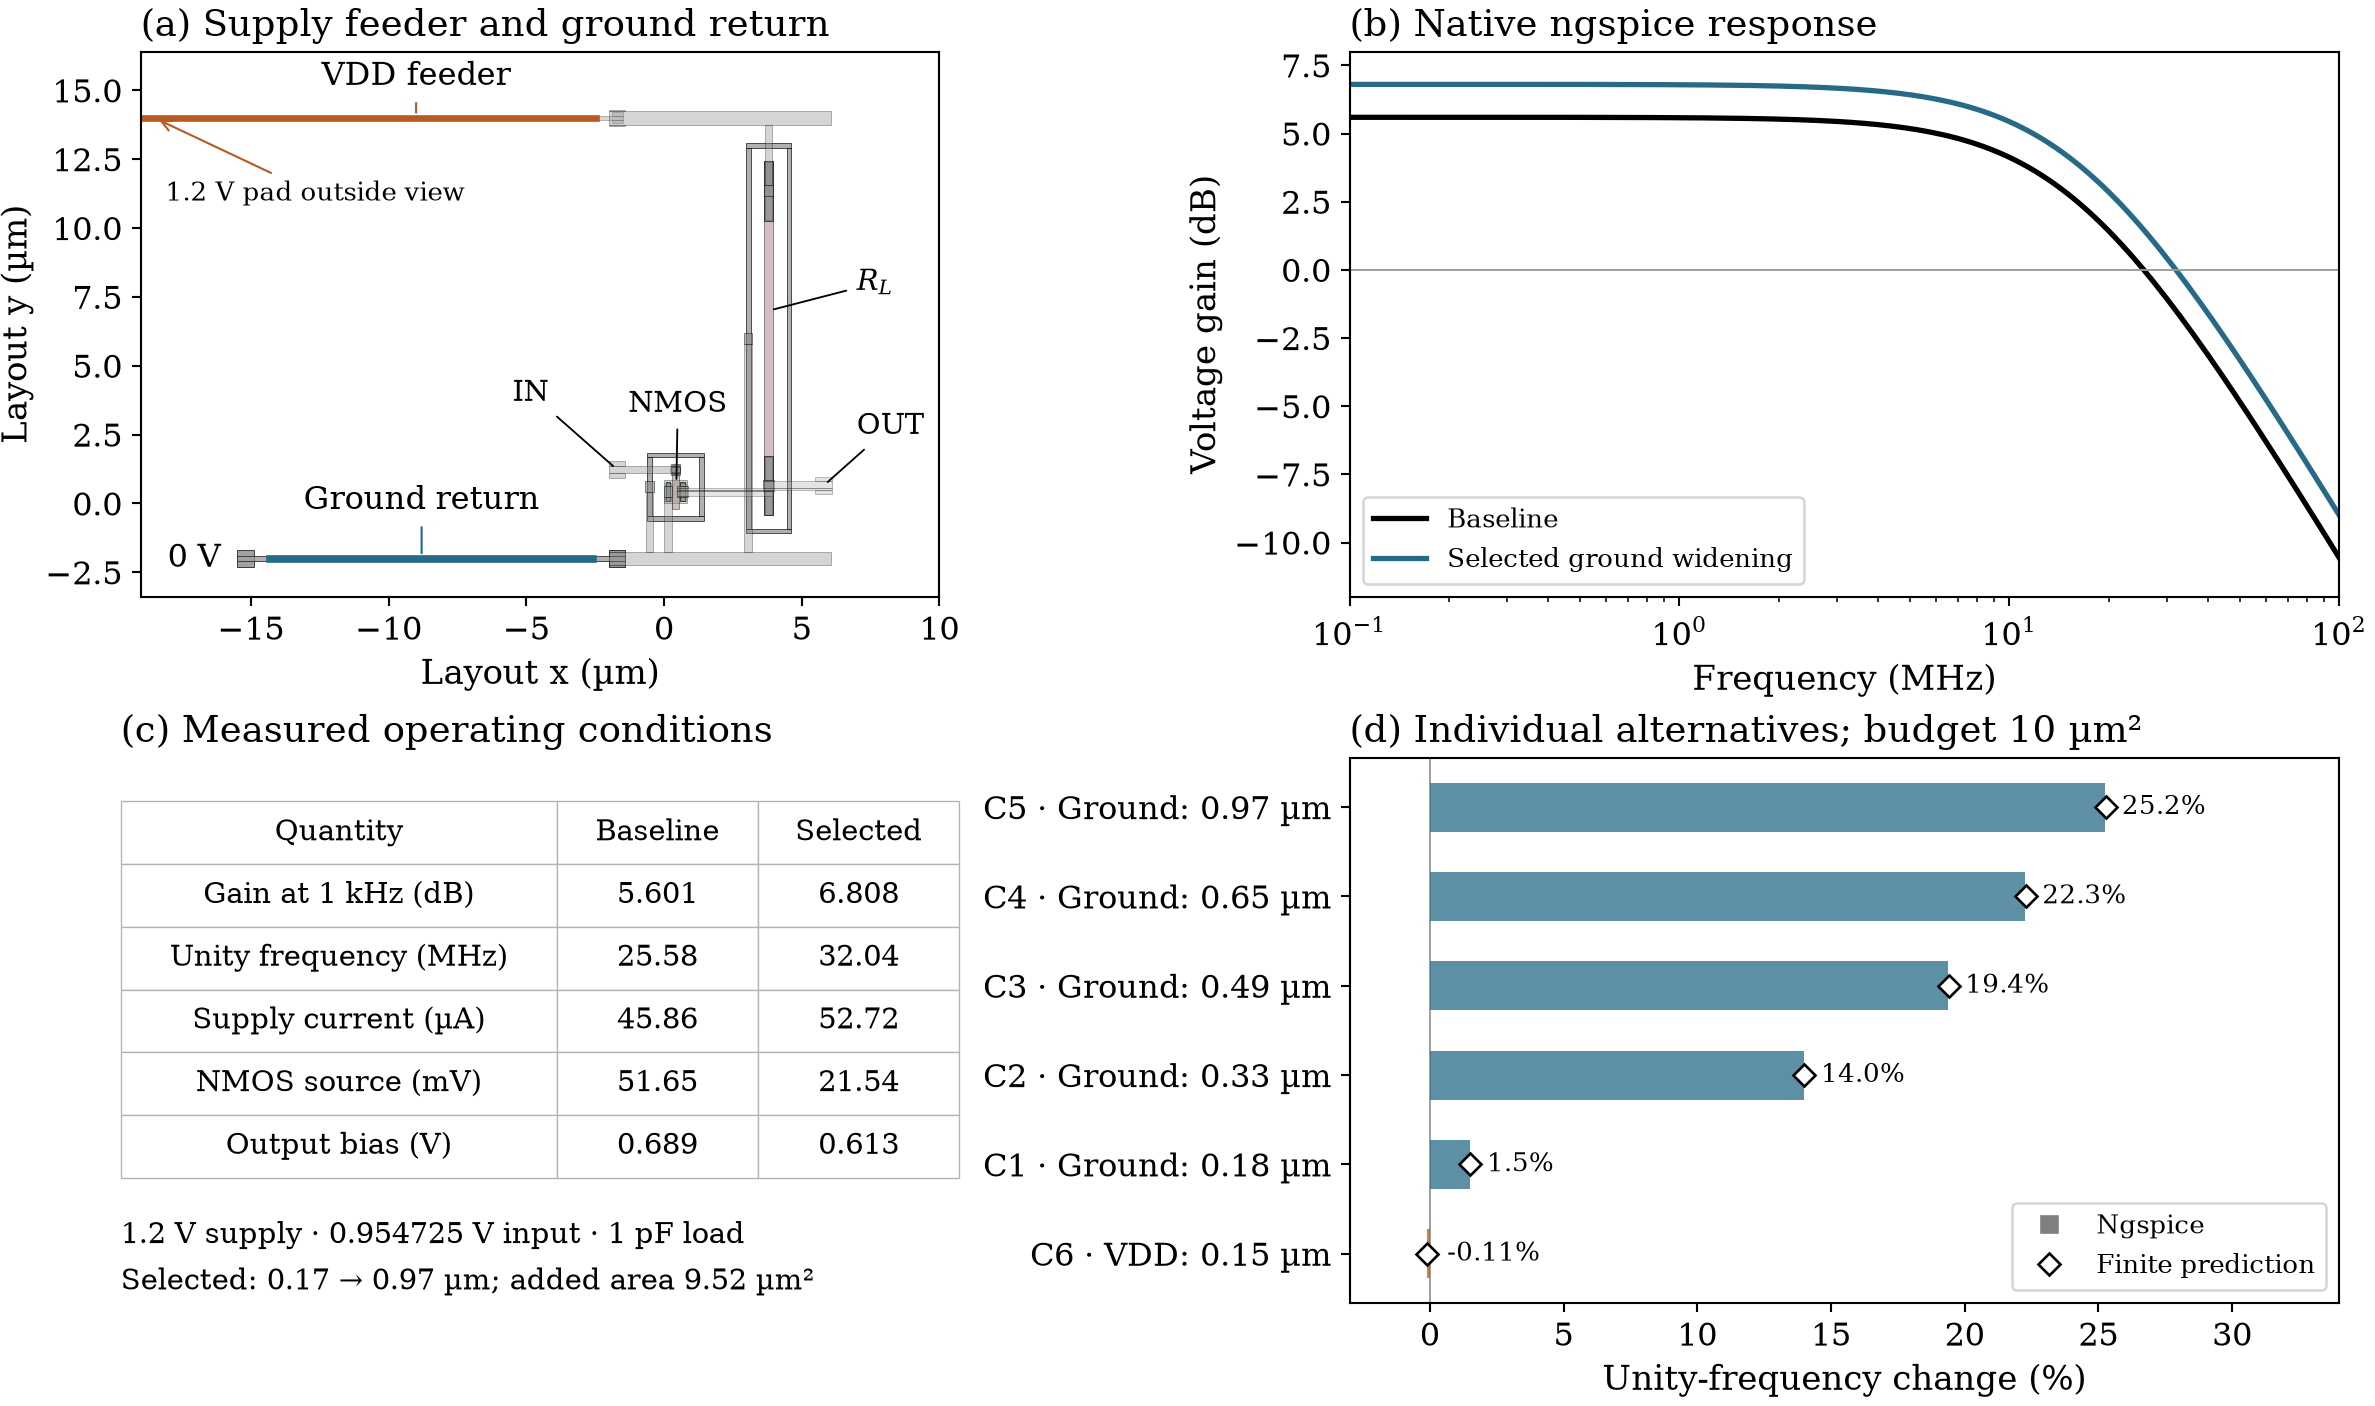

In [16]:
figure("common_source_summary")

*Figure 11. Common-source comparison. (a) Local baseline layout, with the VDD feeder continuing left toward the remote supply pad. (b) Ngspice responses before and after the selected ground widening. (c) Measured operating conditions. (d) Unity-frequency changes for the six individual alternatives under the 10 µm² budget; bars show ngspice measurements and open diamonds show finite predictions. The initial widths are 0.17 µm on the ground return and 0.14 µm on the VDD feeder. Candidate labels match the explorer below.*

Selecting a candidate in the explorer below connects its measured frequency response to the modified route. In the Layout view, the two maps share voltage and coordinate limits, with the original width shown by a dashed outline. The Response view includes metric predictions as points and native frequency sweeps as continuous curves. The default view opens on the selected 9.52 µm² return widening.

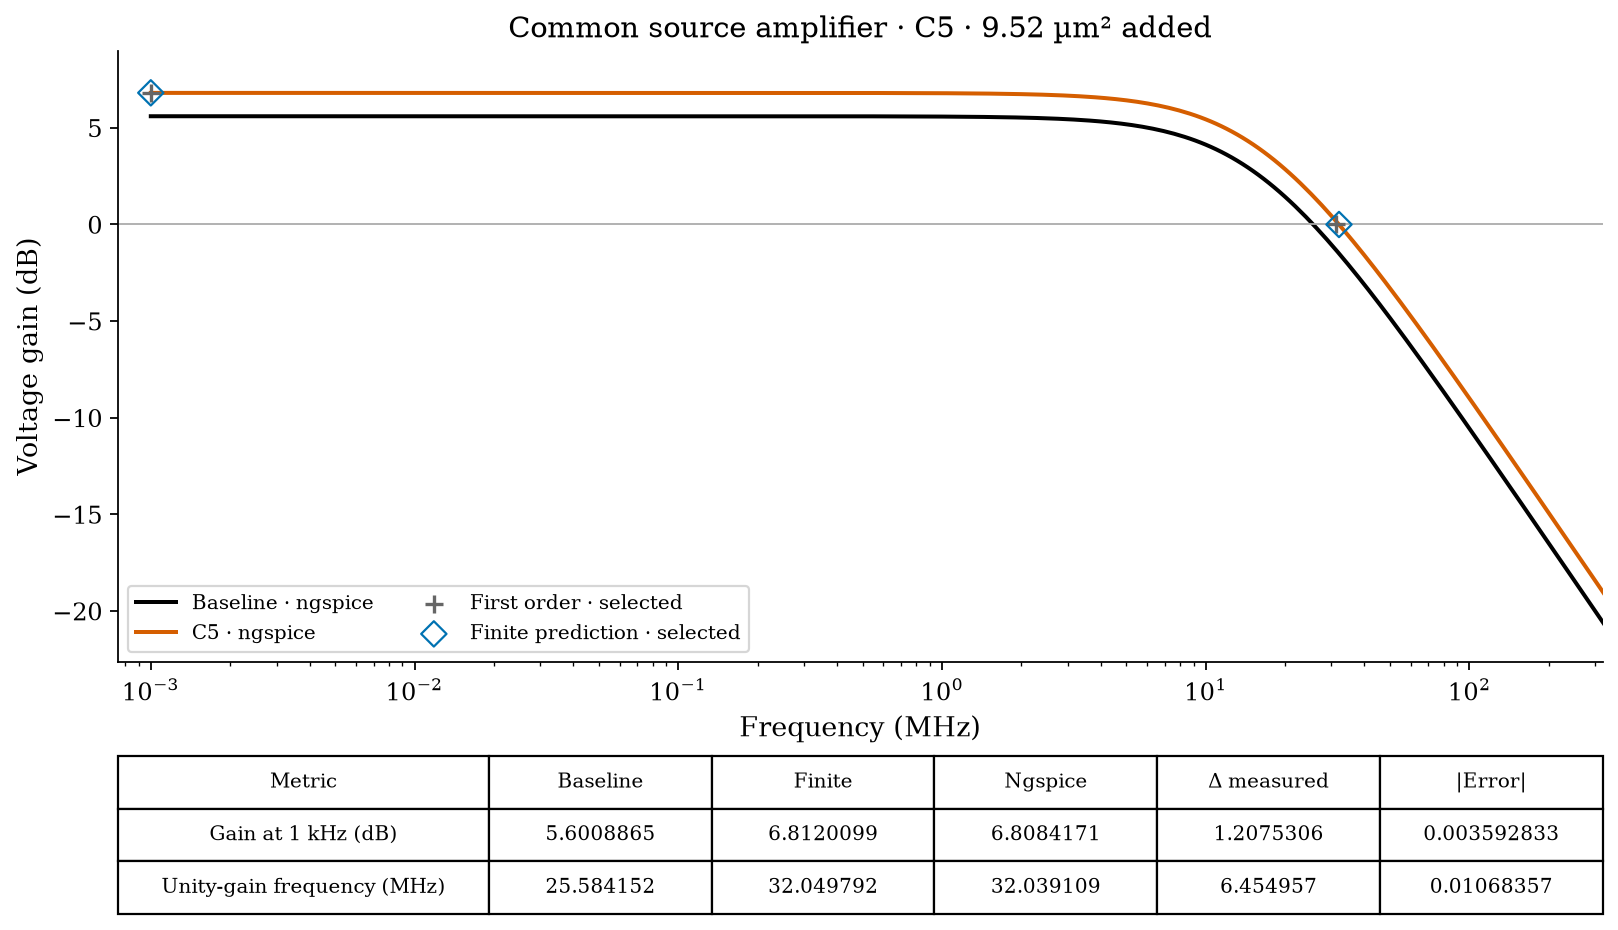

In [17]:
common_source_explorer = show_explorer("common_source_amplifier")

<details>
<summary>Earlier fixed-span checks used in the methods figures</summary>

For the worked AC example in Figure 7, we widened the 12.5 µm common-source return span from 0.17 to 0.49 µm, adding 4 µm². With zero DRC markers and a matching LVS result, the first-order sum of wire and bias derivatives over the associated resistance changes was compared with a separately remeshed ngspice simulation of the complete candidate.

Native gain at 1 kHz increases from 5.60089 to 6.60643 dB, corresponding to a linear-gain increase from 1.90566 to 2.13954 V/V, or 12.27%, and the unity-gain frequency increases from 25.58415 to 30.83154 MHz, or 20.51%. As the local ground voltage falls from 51.65 to 27.10 mV, supply current rises from 45.86 to 51.45 µA. Against these measurements, the first-order estimate of 6.60398 dB and 30.33050 MHz underestimates the unity-frequency improvement by 9.55%, showing the limitation of applying the baseline derivative over this larger change. With the saved fixed-span finite-action estimate of 30.83897 MHz, the error falls to 0.14% of the native frequency improvement. We show the first-order result in the figure so that its contribution table and verification markers refer to the same calculation.

Under the full 10 µm² budget, the separate return-widening selection in Figure 2 gives predicted and measured objective benefits of 1.980 and 1.978. Relative to the same baseline circuit and external conditions used for both width alternatives, linear gain improves by 15.76% and unity-gain frequency by 26.77%, with supply current increasing from 45.86 to 53.14 µA.

</details>

### 5.3 Inverter amplifier

The inverter layout in Figure 12 has separate LI access routes between the external supply boundaries and the local source/body rails. Automatic discovery found an 11.5 µm span on each net, initially 0.17 µm wide. Increasing either span to 0.21, 0.33 or 0.49 µm gives six individual alternatives, with added areas of 0.46, 1.84 and 3.68 µm² under a 4 µm² budget. The configured objective minimizes unity-frequency error relative to 1.2 GHz, with gain constrained to at least 20.5 dB and unity frequency to at least 800 MHz. Gain has zero objective weight in this comparison.

Both predicted and measured ranking selected the 0.49 µm ground route. Its unity-gain frequency increased from 843.57284 to 974.84665 MHz, or 15.56%, and gain increased from 20.93693 to 21.05700 dB. The NMOS source voltage fell from 41.71 to 21.22 mV, increasing its gate-to-source bias under the fixed external input. Supply current rose from 41.51 to 46.73 µA (+12.57%), and output bias moved from 0.931 to 0.777 V. Thus, the bandwidth recovery also changes the circuit's power consumption and output operating point.

At the same 3.68 µm² added area, VDD widening gave 946.40477 MHz (+12.19%) and 20.66733 dB, a 0.270 dB gain decrease. Both alternatives satisfy the configured limits, but ground widening gives the larger bandwidth benefit. Their differing gain changes illustrate why conductor area alone cannot determine the preferred route.

For the selected candidate, the first-order adjoint predicted 954.27822 MHz. Applying the shared finite predictor gave 975.02096 MHz, with an error of 0.17431 MHz, or 0.133% of the measured change. Its gain prediction differed from ngspice by 0.002954 dB, or 2.46% of the measured gain change. All six alternatives passed the configured prediction checks.

Native simulations of the baseline and selected physical layouts at input biases of 0.88, 0.89 and 0.90 V gave 15.35–15.75% bandwidth recovery. These supplementary sweeps used log interpolation of 80 native AC points per decade. At the nominal bias, both devices had more than 0.63 V between $|V_{DS}|$ and the compact model's $|V_{DS,\mathrm{sat}}|$, supporting the comparison away from the saturation boundary.


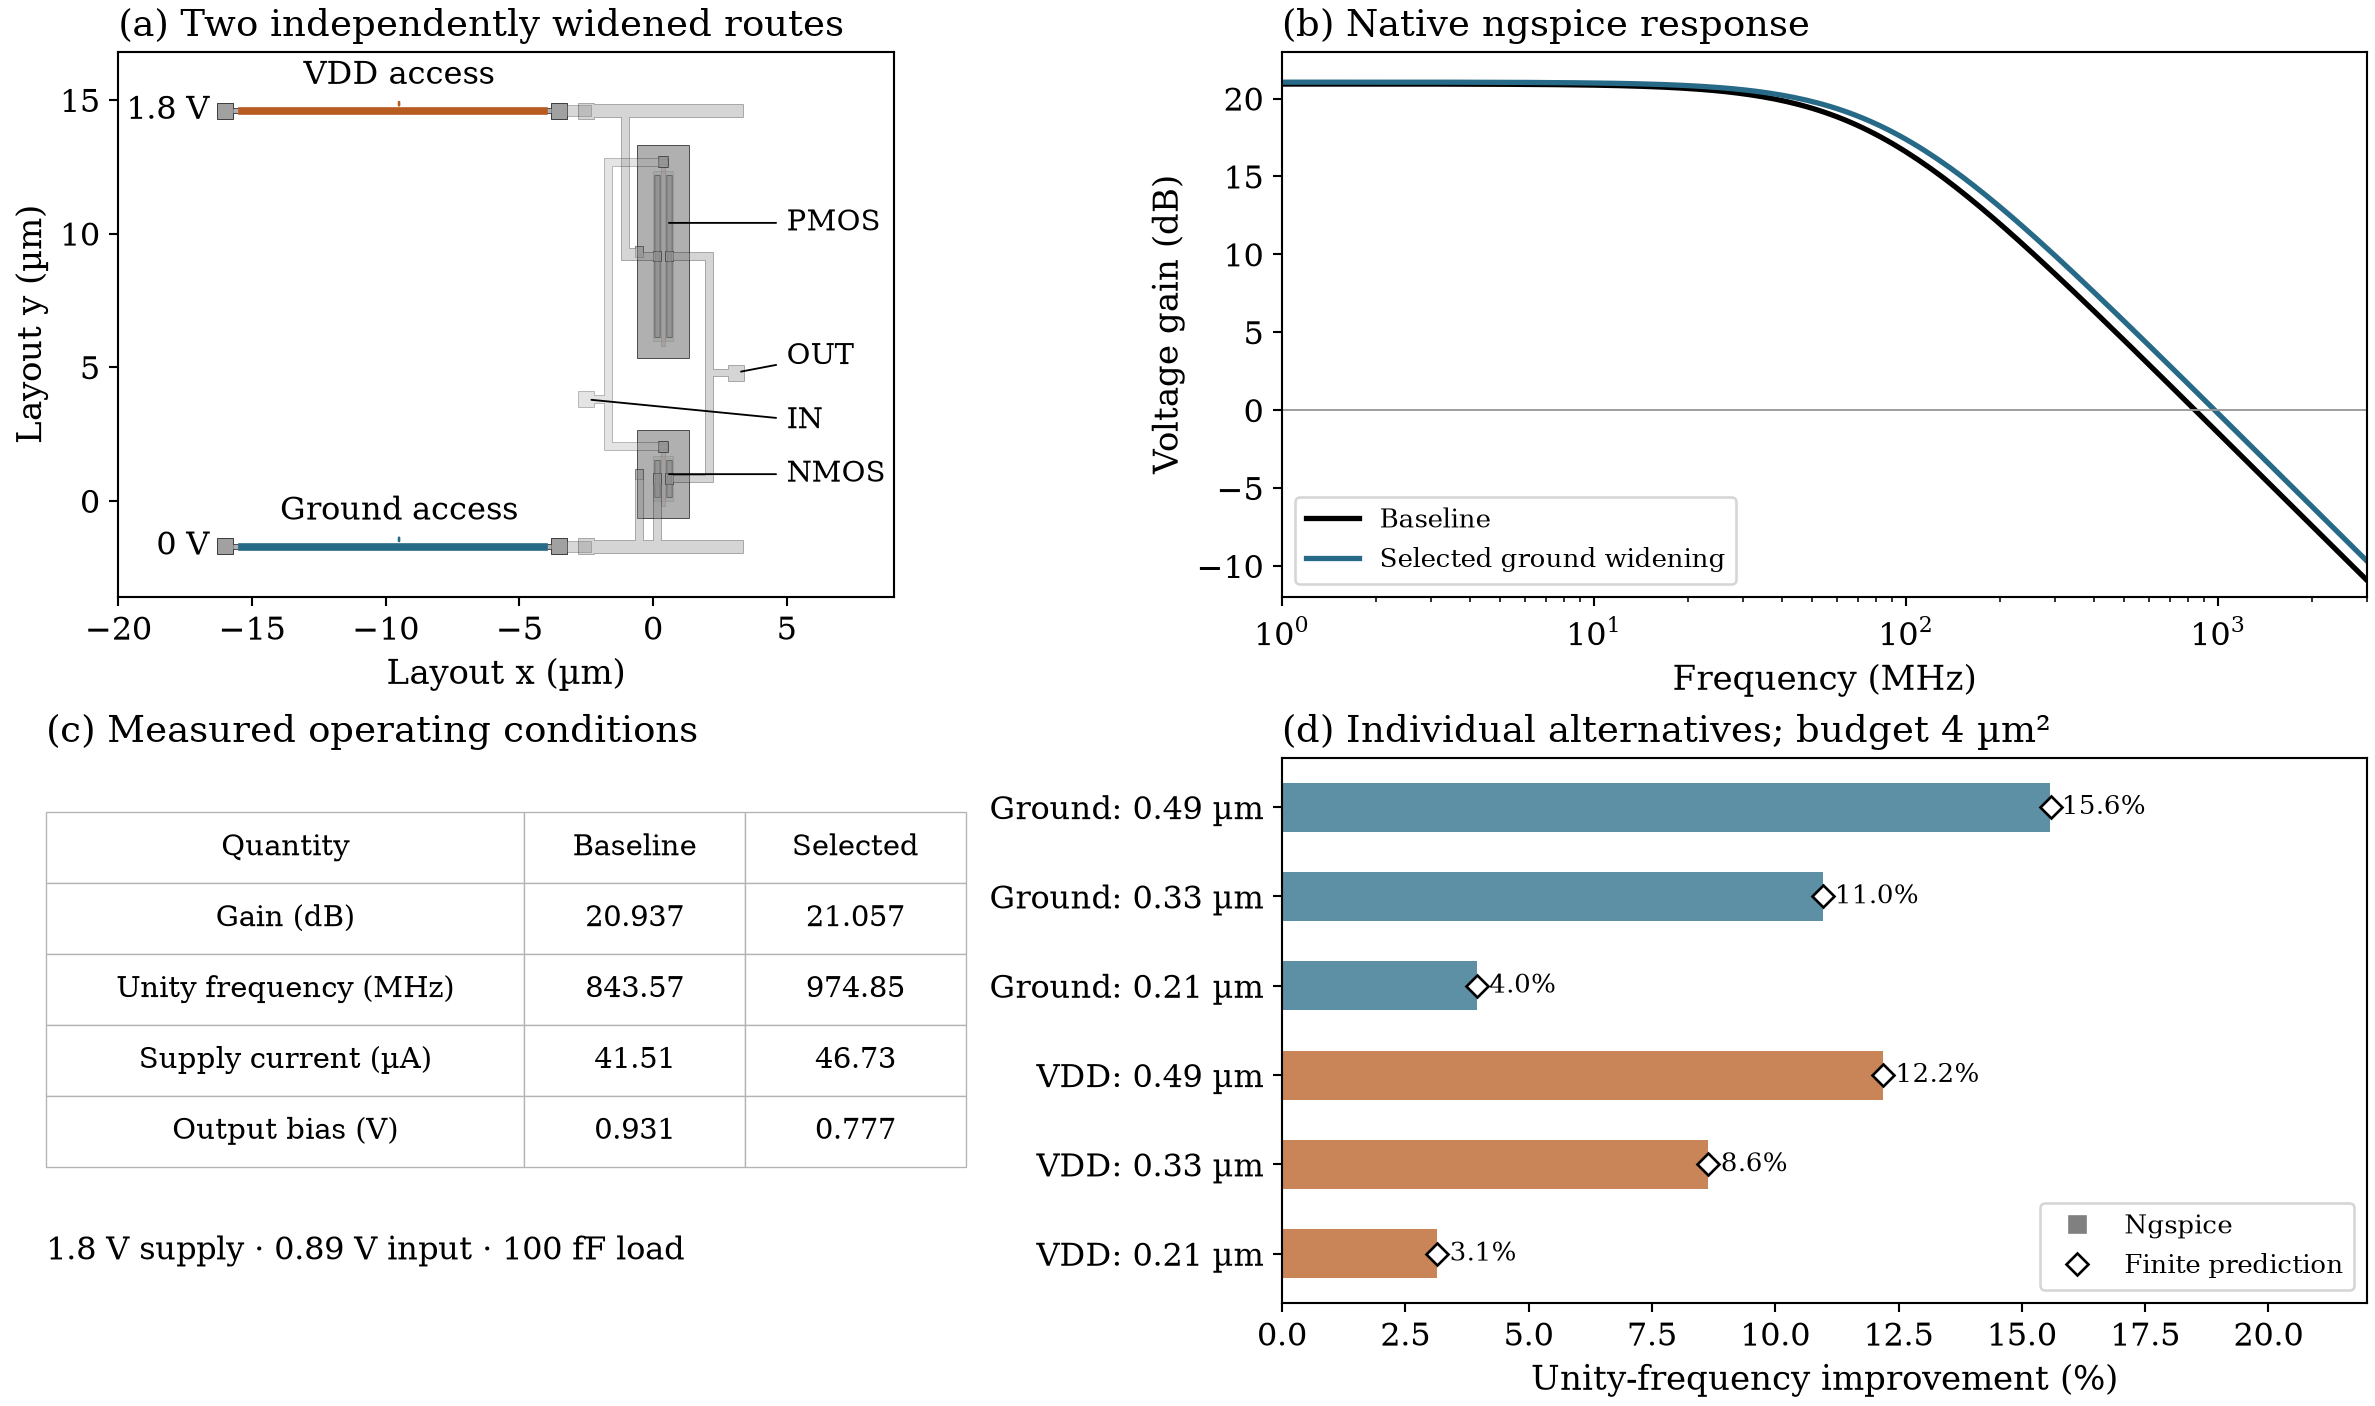

In [18]:
figure("inverter_access_summary")

*Figure 12. Inverter LI-access comparison. (a) Baseline layout with VDD and ground access routes highlighted. (b) Native responses before and after the selected ground widening. (c) Measured operating conditions. (d) Unity-frequency improvement for each individual widening; bars show ngspice measurements and open diamonds show finite predictions. All routes start at 0.17 µm width.*

The explorer opens on the selected ground widening, C3. Candidates C1–C3 widen the ground route to 0.21, 0.33 and 0.49 µm; C4–C6 apply the same widths to VDD. Overlaying C6 provides the equal-area supply comparison. The Candidates view includes the original adjoint estimates, finite predictions, measured values and benefit-per-area table. Choosing gain priority seeks the configured 21 dB target with the same limits, allowing a narrower ground route to become preferable.

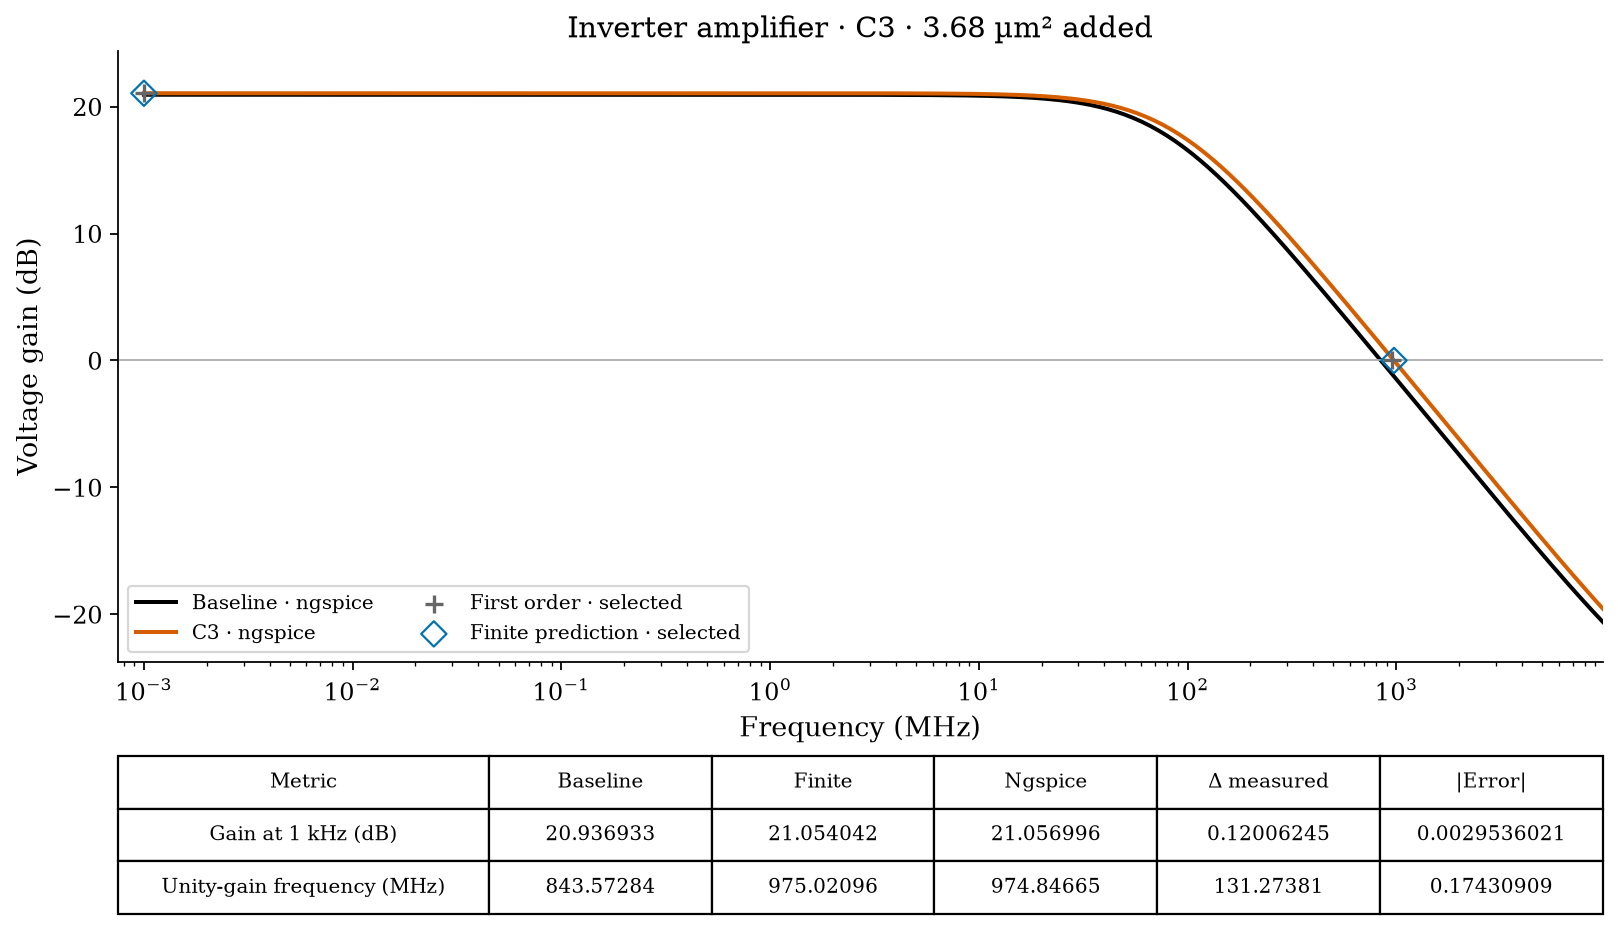

In [19]:
inverter_explorer = show_explorer("inverter_amplifier_access")

<details>
<summary>Earlier Metal 1 feeder comparison</summary>

The earlier inverter study used a 996.8 µm Metal 1 supply span, a 0.89284 V input bias, a 10 fF load and a 60 µm² budget. Its widest alternative added 59.808 µm² and increased unity frequency from 8.97484 to 9.45497 GHz (+5.35%). Gain changed from 21.00789859 to 21.00667910 dB; the finite gain prediction error was 0.000862 dB, about 71% of that small measured change. The [original measurements and provenance](evidence/explorer/inverter_amplifier/study.json) remain available. The LI-access experiment uses different routing and load conditions, so its percentage improvement is measured against its own baseline.

</details>

### 5.4 Exploring and reproducing the comparisons

The controls operate on the supplied measurements. Changing the area budget filters the saved candidate set, and changing metric priority recalculates the objective from the same gain and unity-frequency values. Targets, normalization scales and individual limits remain fixed. Predicted choice and measured best are shown separately, with the preferred individual alternative selected by total benefit. Sorting the table by benefit per area changes its display order.

The slider covers budgets up to the original generation limit and moves between the recorded candidate areas. Wider traces or different design conditions require a new study. Since all twelve alternatives have already been measured, notebook exploration needs only the Python notebook environment; it does not invoke ngspice, KLayout or the PDK.

After running the notebook cells, choose a candidate and switch between Response, Candidates and Layout. Under Plot options, additional measured responses can be overlaid and either prediction can be hidden. Static notebook previews and the exported HTML show the default figures.

New calculations can be run in [Section 6](#native-study). Portable plotting data accompany the fixed comparisons above, with source-file hashes linking them to the original native runs.

<a id="native-study"></a>
## 6 Running a complete study

The complete native records for both amplifier studies are included under `recorded_runs/`. With the default setting below, this section displays their original execution logs, candidate verification tables and saved plots. The records also contain the simulation decks, mesh networks, raw responses, source hashes and DRC/LVS reports, so the full calculation can be inspected before installing the native tools. The recorded views need only the Python notebook environment.

Set `RUN_FULL_STUDY` to `True` to calculate a new study, with `PROJECT_FILE` selecting its circuit and configuration. New calculations require Ubuntu 24.04 or Ubuntu under WSL 2, KLayout 0.30.12, Xschem, the pinned ngspice 47 build and SKY130A installation from [Section 4.1](#installation). The run starts with a tool and PDK check. In the default recorded view, both supplied studies are shown regardless of `PROJECT_FILE`.

The recorded studies took approximately 14 minutes each on the development machine; runtime depends on the hardware and candidate count. Baseline verification and calibration took approximately two minutes before the first candidate message.


In [20]:
# Set True to calculate a new study; False displays both complete recorded runs.
RUN_FULL_STUDY = False
PROJECT_FILE = ROOT / "examples/inverter_amplifier/project_access.json"
# Alternative: ROOT / "examples/common_source_amplifier/project.json"
STUDY_DIRS = []


For a new calculation, the execution cell calls the shared runner. Schematic export and baseline DRC/LVS are followed by meshing, connected DC and AC simulation, and metric adjoints. Automatically generated widenings undergo layout checks, remeshing and finite-change prediction. With `--verify-all`, ngspice measures every successfully refined candidate, including alternatives with negative predicted benefit. Predictions are saved before candidate measurements.

A new run creates a dated directory under `output/<project>/unified/`. Progress appears below as candidates complete, and native logs are written inside that directory. Interrupting the cell stops its launched tools. In the default mode, the console text below comes from the recorded executions identified in [the run index](../recorded_runs/index.json).


In [21]:
import json, os, signal, subprocess
from datetime import datetime, timezone

STUDY_DIRS = []
if RUN_FULL_STUDY:
    if not sys.platform.startswith("linux"):
        raise RuntimeError("Use the Ubuntu/WSL Python kernel for native circuit tools.")
    config = json.loads(PROJECT_FILE.read_text())
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
    destination = ROOT / "output" / config["name"] / "unified" / stamp
    print("New study:", destination, flush=True)
    print("Checking tools; baseline DRC/LVS and calibration run before candidate progress.", flush=True)
    # Pass paths as arguments so spaces are safe; use the same PDK environment as the CLI.
    command = ["bash", "--noprofile", "--norc", "-c",
               'set -e; source scripts/env.sh; '
               '"$1" -u scripts/check_environment.py; '
               'exec "$1" -u scripts/perfpdn.py run "$2" --output "$3" --verify-all',
               "perfpdn-notebook", sys.executable, str(PROJECT_FILE), str(destination)]
    with subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True, start_new_session=True) as process:
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
            status = process.wait()
        except KeyboardInterrupt:
            # Interrupt the whole launched tool group, including any active KLayout or ngspice process.
            os.killpg(process.pid, signal.SIGTERM)
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                os.killpg(process.pid, signal.SIGKILL)
                process.wait()
            raise
    if status:
        raise RuntimeError(f"Study stopped with exit status {status}. See the output above and any logs under {destination}.")
    STUDY_DIRS = [destination]
else:
    recorded = ROOT / "recorded_runs"
    catalog = json.loads((recorded / "index.json").read_text())
    STUDY_DIRS = [recorded / name for name in catalog]
    for name, info in catalog.items():
        print("\nRecorded native execution:", info["label"])
        print((recorded / info["console"]).read_text(), flush=True)



Recorded native execution: Common-source amplifier
Baseline: {'gain_dB': 5.6008865163113795, 'unity_Hz': 25584151.79035413}
li_x_000_w04 predicted {'gain_dB': 6.812009932539378, 'unity_Hz': 32049792.373869818}
li_x_000_w03 predicted {'gain_dB': 6.6852214345693035, 'unity_Hz': 31286316.734549645}
li_x_000_w02 predicted {'gain_dB': 6.558391480423806, 'unity_Hz': 30547520.627666216}
li_x_000_w01 predicted {'gain_dB': 6.310026573192717, 'unity_Hz': 29164516.3389581}
li_x_000_w00 predicted {'gain_dB': 5.680835036868768, 'unity_Hz': 25964975.60483113}
m1_x_001_w00 predicted {'gain_dB': 5.565536167525944, 'unity_Hz': 25556626.346407194}
li_x_000_w04 ngspice {'gain_dB': 6.808417099501619, 'unity_Hz': 32039108.803453367}
li_x_000_w03 ngspice {'gain_dB': 6.682350045026162, 'unity_Hz': 31277744.26874304}
li_x_000_w02 ngspice {'gain_dB': 6.5561410724816005, 'unity_Hz': 30540783.821180027}
li_x_000_w01 ngspice {'gain_dB': 6.308736635727299, 'unity_Hz': 29160652.83580139}
li_x_000_w00 ngspice {'gai


Recorded native execution: Inverter amplifier
New study: /home/gokalp/projects/PerfPDN/output/submission/20261030_205357/PerfPDN/output/inverter_amplifier_access/unified/20261030_210740_715481
Checking tools; baseline DRC/LVS and calibration run before candidate progress.
Python: 3.12.3
numpy: 2.5.3
scipy: 1.18.1
matplotlib: 3.11.2
klayout: 0.30.12
gdsfactory: 8.20.0
ciel: 3.0.0
git: /usr/bin/git
klayout: /usr/bin/klayout
xschem: /usr/bin/xschem
******
** ngspice-47 : Circuit level simulation program
** Compiled with KLU Direct Linear Solver
** The U. C. Berkeley CAD Group
** Copyright 1985-1994, Regents of the University of California.
** Copyright 2001-2026, The ngspice team.
** Please get your ngspice manual from https://ngspice.sourceforge.io/docs.html
** Please file your bug-reports at http://ngspice.sourceforge.net/bugrep.html
** Creation Date: Mon Oct 26 03:43:39 UTC 2026
******
SKY130: /home/gokalp/.local/share/perfpdn/pdks/sky130A
Tool locations are ready. Run uv run --locked

The results cell reads each completed study and shows its prediction and measurement coverage, DRC/LVS status, metric limits and prediction-error checks. In recorded mode, all twelve candidate measurements and the saved response plots are displayed. A new calculation displays the results from its own output directory.

Within each study, `results.json` and `candidates.csv` contain the measurements and ranking. Baseline checks are under `verification/`; every candidate has its layout, prediction, DRC/LVS reports and measurement logs under `candidates/<id>/`. The copied native records keep their original paths and hashes as provenance. The notebook and plotting command read the included files relative to the study directory.



common_source_amplifier
Results: recorded_runs/common_source_amplifier
Prediction coverage: {'generated': 6, 'refined': 6}
Measured candidates: 6/6 requested
Selected: li_x_000_w04


Candidate,Area (µm²),DRC/LVS,Prediction error,Metric limits,Status
li_x_000_w04,9.52,Pass,Pass,Pass,verified
li_x_000_w03,5.712,Pass,Pass,Pass,verified
li_x_000_w02,3.808,Pass,Pass,Pass,verified
li_x_000_w01,1.904,Pass,Pass,Pass,verified
li_x_000_w00,0.119,Pass,Pass,Pass,verified
m1_x_001_w00,9.998,Pass,Pass,Pass,verified


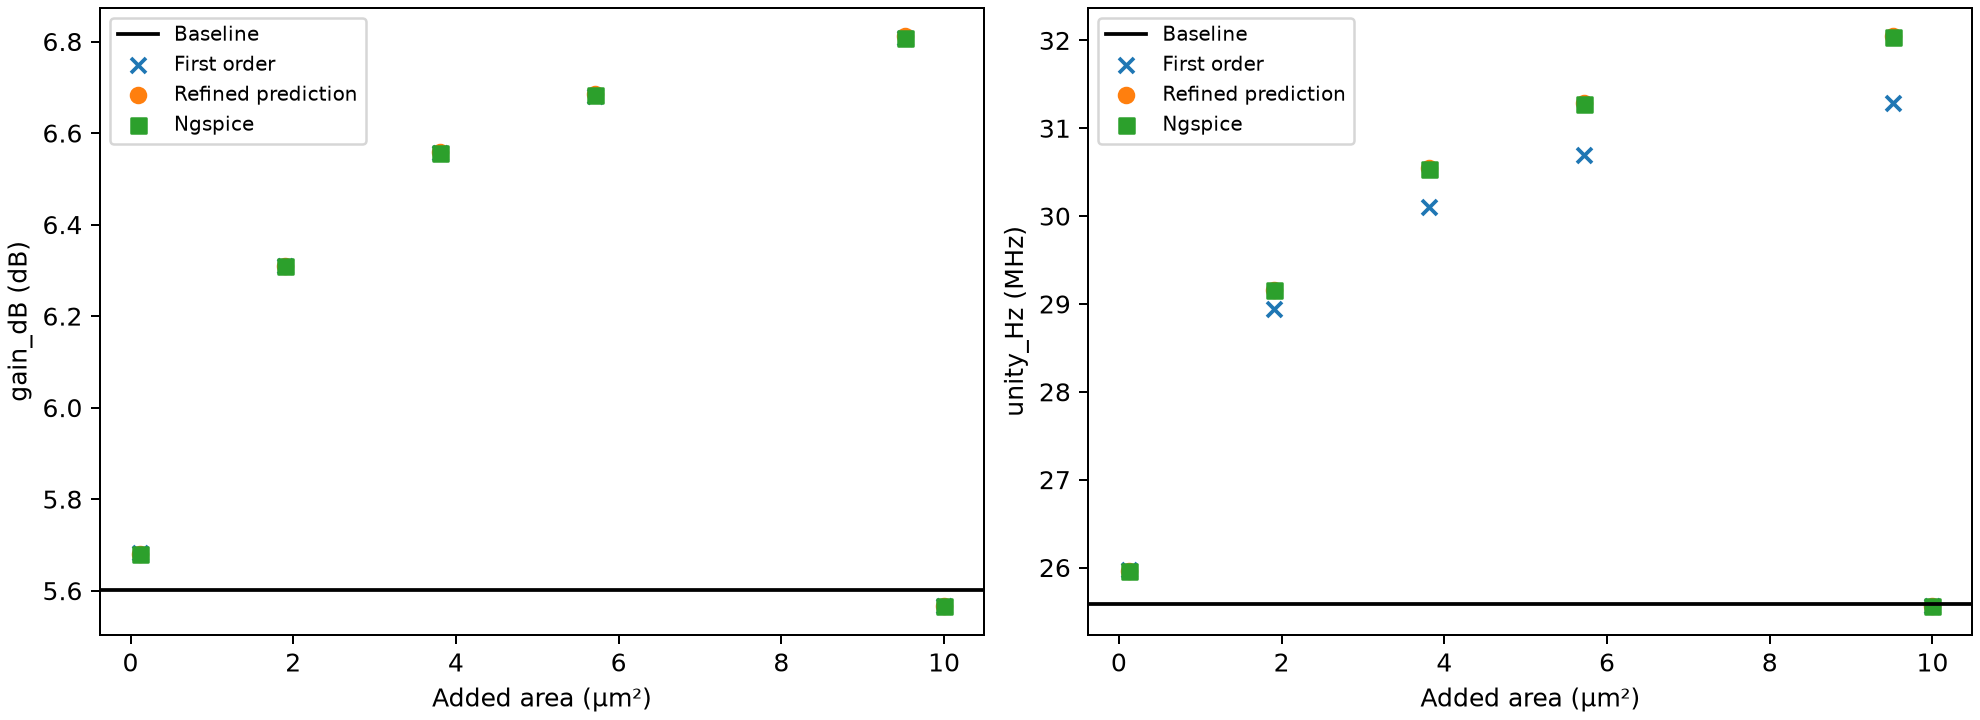

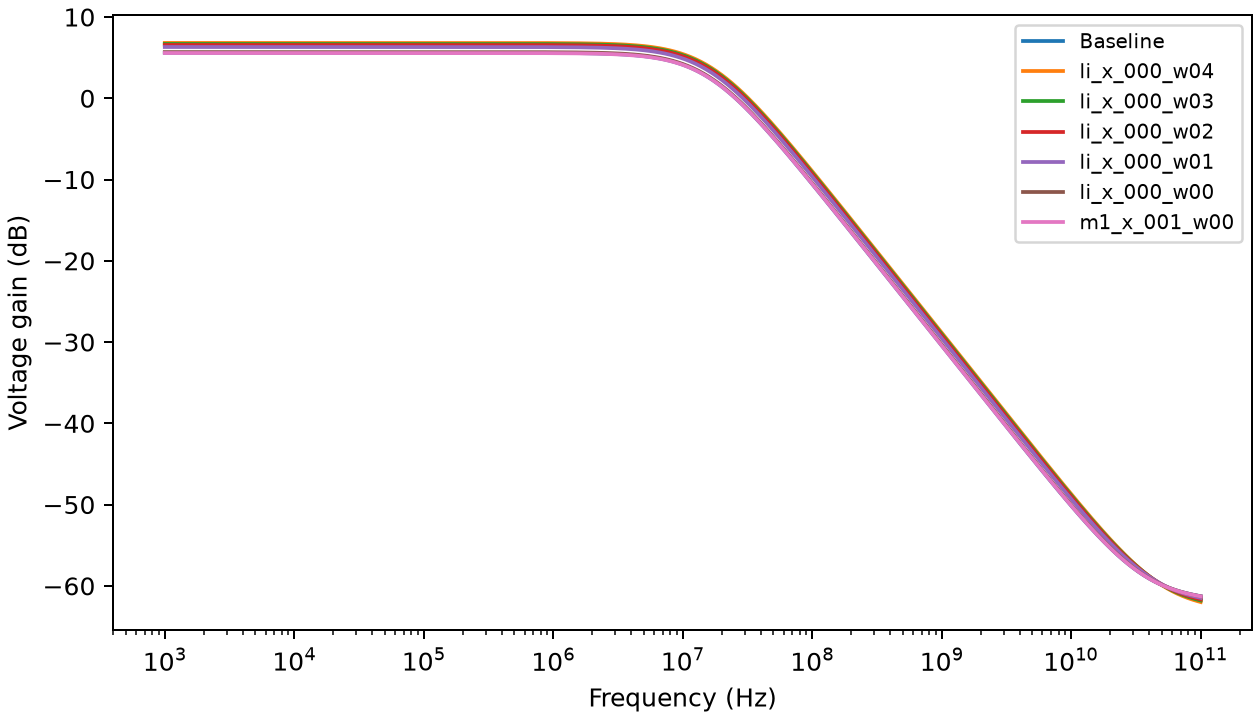


inverter_amplifier_access
Results: recorded_runs/inverter_amplifier_access
Prediction coverage: {'generated': 6, 'refined': 6}
Measured candidates: 6/6 requested
Selected: li_x_000_w02


Candidate,Area (µm²),DRC/LVS,Prediction error,Metric limits,Status
li_x_000_w02,3.68,Pass,Pass,Pass,verified
li_x_001_w02,3.68,Pass,Pass,Pass,verified
li_x_000_w01,1.84,Pass,Pass,Pass,verified
li_x_001_w01,1.84,Pass,Pass,Pass,verified
li_x_000_w00,0.46,Pass,Pass,Pass,verified
li_x_001_w00,0.46,Pass,Pass,Pass,verified


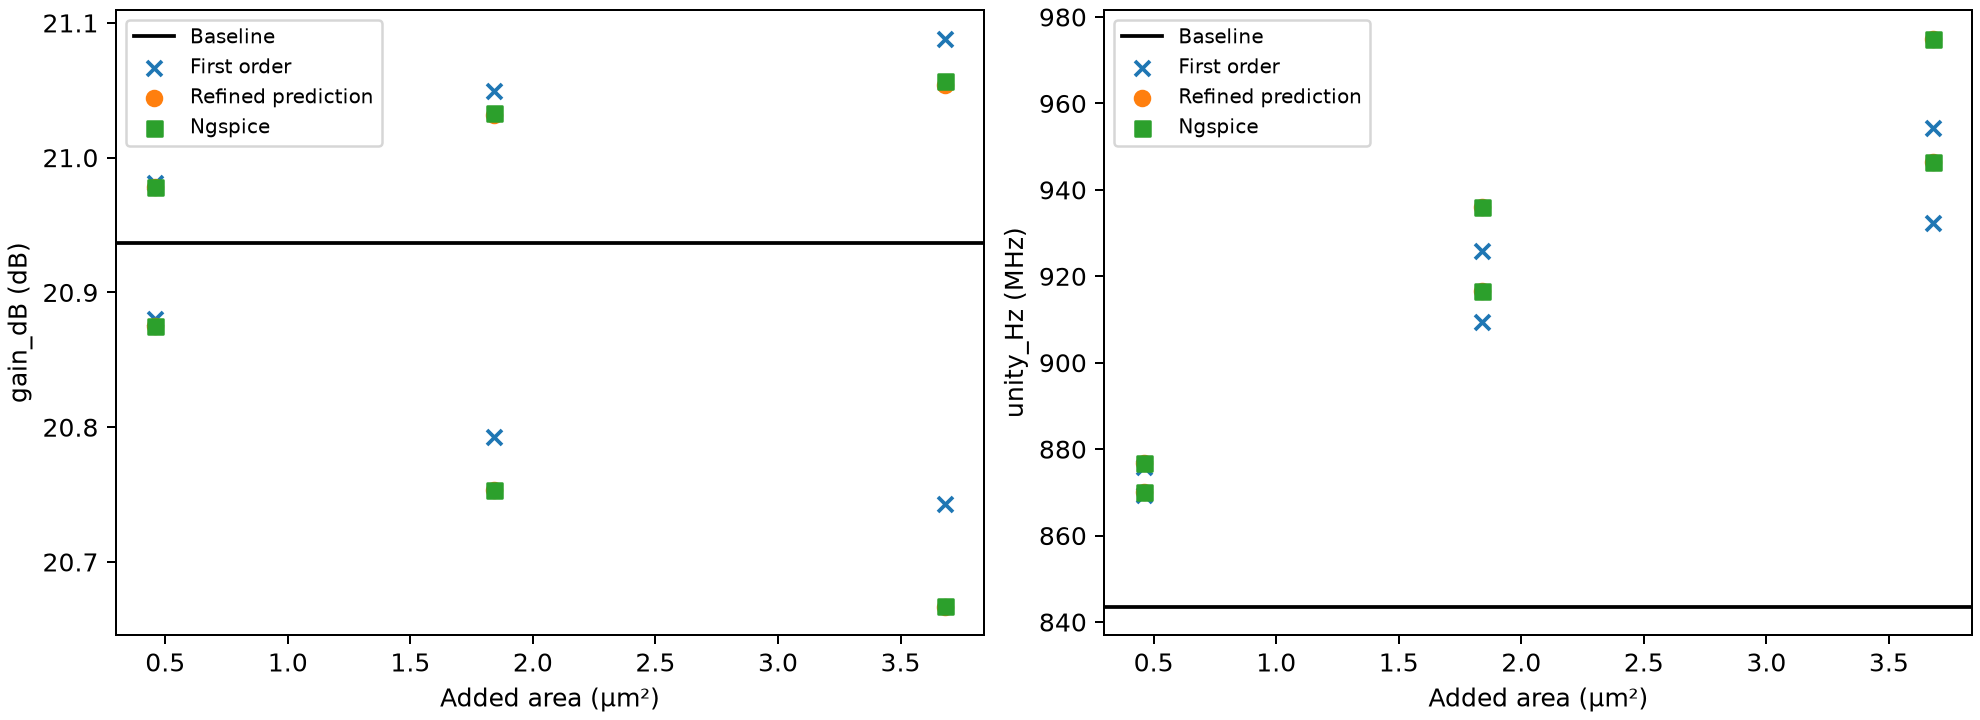

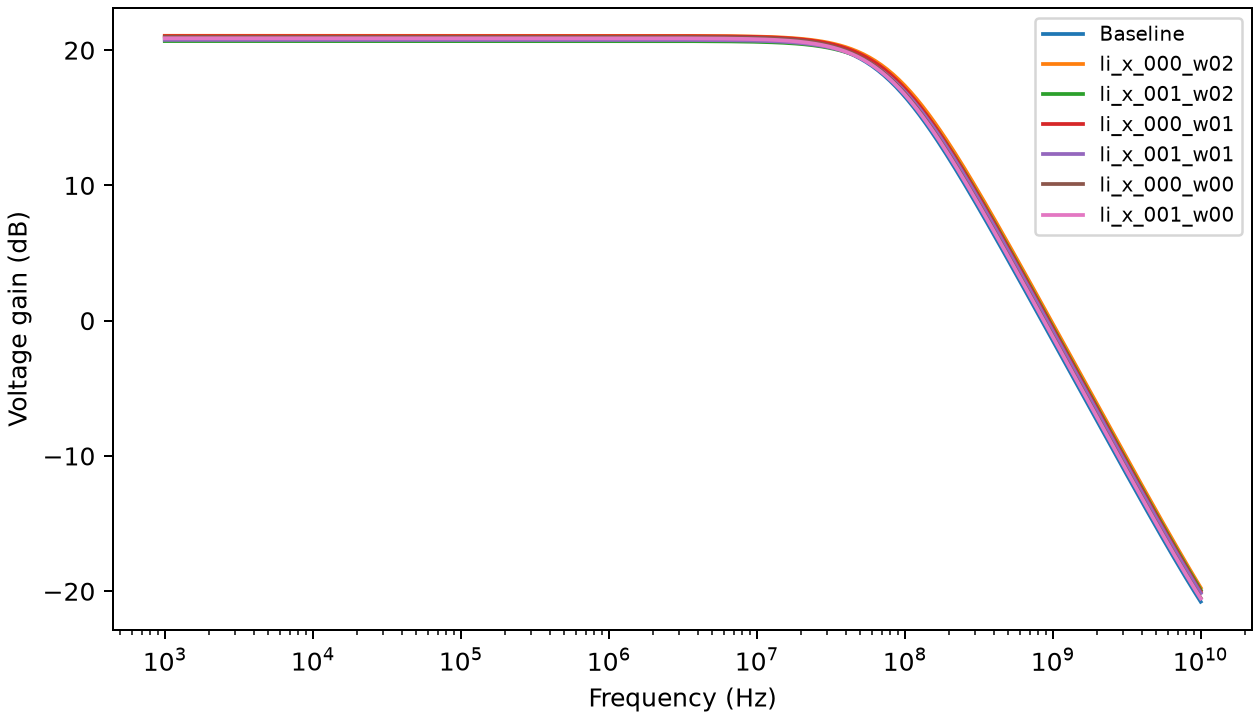

In [22]:
from IPython.display import HTML, Image, display
from result_explorer import table

for STUDY_DIR in STUDY_DIRS:
    result = json.loads((STUDY_DIR / "results.json").read_text())
    coverage = result["verification_coverage"]
    print("\n" + result["project"]["name"])
    print("Results:", STUDY_DIR.relative_to(ROOT))
    print("Prediction coverage:", result["prediction_coverage"])
    print(f'Measured candidates: {coverage["measured"]}/{coverage["requested"]} requested')
    print("Selected:", result["selected"])
    rows = []
    for candidate in result["candidates"]:
        path = STUDY_DIR / "candidates" / candidate["id"] / "verification/verification.json"
        proof = json.loads(path.read_text()) if path.is_file() else {}
        checked = proof.get("drc_markers") == 0 and proof.get("lvs_status") == "Match"
        errors = candidate.get("prediction_errors", {})
        limits = candidate.get("measured_constraints", {})
        reason = candidate.get("verification_error", candidate.get("reason", ""))
        rows.append([candidate["id"], f'{candidate["geometry"]["added_area_um2"]:.4g}',
                     "Pass" if checked else "See log",
                     ("Pass" if all(e["passed"] for e in errors.values()) else "Outside tolerance") if errors else "—",
                     ("Pass" if limits["passed"] else "; ".join(limits["failures"])) if limits else "—",
                     candidate["status"] + (": " + reason if reason else "")])
    display(HTML(table(["Candidate", "Area (µm²)", "DRC/LVS", "Prediction error", "Metric limits", "Status"], rows)))
    for name in ("candidate_metrics.png", "bode.png"):
        display(Image(filename=str(STUDY_DIR / name)))


<a id="conclusion"></a>
## 7 Conclusion

Interconnect widening can be directed by its effect on circuit performance once the layout and devices are solved as a connected electrical model. In the two SKY130 amplifier studies, the shared workflow selected ground widenings that increased unity-gain frequency by 25.23% for the common-source amplifier and 15.56% for the inverter amplifier under their respective area budgets. The baseline and candidate layouts passed DRC/LVS, and full ngspice simulations verified the predicted improvements. The associated increase in supply current shows why performance recovery should be considered together with power consumption.


<a id="references"></a>
## References

<p id="ref-gala2003">[1] K. H. Gala, H. Su, and S. S. Sapatnekar, “Analysis and optimization of structured power/ground networks,” IEEE Trans. Computer-Aided Design Integr. Circuits Syst., vol. 22, no. 11, pp. 1533–1544, 2003. <a href="https://doi.org/10.1109/TCAD.2003.818372">Source</a>.</p>

<p id="ref-kawakami2008">[2] Y. Kawakami, M. Terao, M. Fukui, and S. Tsukiyama, “A power grid optimization algorithm by observing timing error risk by IR drop,” IEICE Trans. Fundamentals, vol. E91-A, no. 12, pp. 3423–3430, 2008. <a href="https://doi.org/10.1093/ietfec/e91-a.12.3423">Source</a>.</p>

<p id="ref-eymard2000">[3] R. Eymard, T. Gallouët, and R. Herbin, “Finite volume methods,” in Handbook of Numerical Analysis, vol. VII, P. G. Ciarlet and J. L. Lions, Eds., pp. 713–1020, 2000. <a href="https://www.i2m.univ-amu.fr/perso/thierry.gallouet/publi.d/publi03.html">Source</a>.</p>

<p id="ref-sky130">[4] SkyWater PDK authors, “SKY130 process design kit documentation: Parasitic layout extraction and device details.” Accessed Oct. 28, 2026. <a href="https://skywater-pdk.readthedocs.io/en/main/rules/rcx.html">Source</a>.</p>

<p id="ref-openpdks">[5] T. Edwards and open_pdks contributors, “open_pdks: SKY130 technology integration,” revision 1e3554706ddbb2529193bdabbc7128296f3cb44a. The generated sky130A Magic technology file supplies this study&#x27;s typical resistance values. <a href="https://github.com/RTimothyEdwards/open_pdks/tree/1e3554706ddbb2529193bdabbc7128296f3cb44a/sky130">Source</a>.</p>

<p id="ref-ho1975">[6] C.-W. Ho, A. E. Ruehli, and P. A. Brennan, “The modified nodal approach to network analysis,” IEEE Trans. Circuits Syst., vol. 22, no. 6, pp. 504–509, 1975. <a href="https://doi.org/10.1109/TCS.1975.1084079">Source</a>.</p>

<p id="ref-ngspice">[7] Ngspice developers, “Ngspice user&#x27;s manual,” version 47. The historical mirror study uses version 42; the amplifier studies use version 47. Accessed Oct. 28, 2026. <a href="https://ngspice.sourceforge.io/docs/ngspice-47-manual.pdf">Source</a>.</p>

<p id="ref-director1969">[8] S. W. Director and R. A. Rohrer, “The generalized adjoint network and network sensitivities,” IEEE Trans. Circuit Theory, vol. 16, no. 3, pp. 318–323, 1969. <a href="https://doi.org/10.1109/TCT.1969.1082965">Source</a>.</p>

<p id="ref-dorfler2013">[9] F. Dörfler and F. Bullo, “Kron reduction of graphs with applications to electrical networks,” IEEE Trans. Circuits Syst. I, vol. 60, no. 1, pp. 150–163, 2013. <a href="https://doi.org/10.1109/TCSI.2012.2215780">Source</a>.</p>

<p id="ref-scipy2020">[10] P. Virtanen et al., “SciPy 1.0: Fundamental algorithms for scientific computing in Python,” Nature Methods, vol. 17, pp. 261–272, 2020. <a href="https://doi.org/10.1038/s41592-019-0686-2">Source</a>.</p>

<p id="ref-numpy2020">[11] C. R. Harris et al., “Array programming with NumPy,” Nature, vol. 585, pp. 357–362, 2020. <a href="https://doi.org/10.1038/s41586-020-2649-2">Source</a>.</p>

<p id="ref-klayout">[12] M. Köfferlein and KLayout contributors, “KLayout documentation: Geometry processing, design-rule checking and layout-versus-schematic,” version 0.30.12. Accessed Oct. 28, 2026. <a href="https://www.klayout.de/doc-qt5/manual/lvs_intro.html">Source</a>.</p>

<p id="ref-xschem">[13] S. Schippers and Xschem contributors, “Xschem schematic capture and netlisting documentation.” Checked application version 3.4.4. Accessed Oct. 28, 2026. <a href="https://xschem.sourceforge.io/stefan/index.html">Source</a>.</p>